In [1]:
import os
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from obtain_allocation import *
from project import *
from generate_gaussian import *
from study_results_per_line import *
from fussion_gauss import *

In [2]:
files_stops = files = os.listdir("../data/E01_toA")


timeslot = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]


columns = []

columns.append("Stop")

#For each timeslot t add columns Mean_t, std_t and IsNormal_t
for time in timeslot:
    strvar = f"Mean_boards_{time}"
    columns.append(strvar)
    strvar = f"std_boards_{time}"
    columns.append(strvar)
    strvar = f"IsNormal_boards_{time}"
    columns.append(strvar)
    strvar = f"instances_boards_{time}"
    columns.append(strvar)
    strvar = f"Mean_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"std_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"IsNormal_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"instances_dropoffs_{time}"
    columns.append(strvar)

#generate df
final_dataframe = pd.DataFrame(columns=columns)





for file in files_stops:
    if file != "RESULTS" and file != "NEW":



        dataframe = pd.read_csv("../data/E01_toA/" + file, encoding="utf-8", header=0)
        dataframe = clean_dataframe(dataframe, 2)

        #new_dataframe = generate_gaussian_per_slot_daily(dataframe, "Occupation")

        dataframe = clean_dataframe_advanced(dataframe, "LA")

        unique_days = dataframe["EventDate"].unique()



        list_per_stop = [dataframe["Stop"].unique()[0]]
        for timeslot_iter in timeslot:
            data_timestamp = dataframe[dataframe["TimeSlot.1"] == timeslot_iter]

            list_boards = []
            list_dropoffs = []
            for day in unique_days:
                data_daily = data_timestamp[data_timestamp["EventDate"] == day]
                list_boards.append(sum(data_daily["Board"]))
                list_dropoffs = list_dropoffs +  [data for data in (data_daily["DropOff"])]


            hyp_boards, instances_boards, mean_boards, std_boards = is_normal_simplified(list_boards)
            hyp_drops, instances_drops, mean_drops, std_drops = is_normal_simplified(list_dropoffs)

            eith_tuple = (mean_boards, std_boards, hyp_boards, instances_boards, mean_drops, std_drops, hyp_drops, instances_drops)

            list_per_stop = list_per_stop + [var for var in eith_tuple]


        final_dataframe.loc[len(final_dataframe)] = list_per_stop



with open ("../data/E01_toA/RESULTS/FINAL_results_BOARD_DROPOFF.csv", "w", encoding="utf-8") as f:
    final_dataframe.to_csv(f, index=False)

/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:41: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:38: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:41: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:38: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3


In [3]:
final_dataframe

,Stop,Mean_boards_5,std_boards_5,IsNormal_boards_5,instances_boards_5,Mean_dropoffs_5,std_dropoffs_5,IsNormal_dropoffs_5,instances_dropoffs_5,Mean_boards_6,...,IsNormal_dropoffs_22,instances_dropoffs_22,Mean_boards_23,std_boards_23,IsNormal_boards_23,instances_boards_23,Mean_dropoffs_23,std_dropoffs_23,IsNormal_dropoffs_23,instances_dropoffs_23
0,2646,1.072581,3.754940,False,"[16, 12, 21, 8, 12, 11, 16, 10, 0, 13, 0, 0, 1...",0.000000,0.000000,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",30.250000,...,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.451613,2.707084,False,"[0, 0, 0, 0, 2, 22, 2, 0, 8, 7, 1, 0, 0, 0, 0,...",0.000000,0.000000,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,562,31.475806,14.085833,True,"[38, 35, 28, 40, 43, 16, 24, 26, 19, 30, 32, 4...",0.007380,0.085590,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",37.120968,...,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.967742,1.570574,False,"[1, 0, 2, 2, 0, 3, 1, 0, 2, 1, 0, 3, 0, 0, 4, ...",0.074468,0.333880,False,"[0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, ..."
2,2539,8.967742,8.057190,False,"[8, 9, 16, 13, 21, 6, 34, 23, 16, 13, 5, 23, 9...",0.457364,0.816570,False,"[0, 0, 3, 0, 0, 1, 0, 0, 2, 0, 0, 0, 2, 1, 1, ...",11.120968,...,True,"[7, 0, 3, 2, 6, 5, 2, 1, 4, 4, 4, 5, 5, 3, 3, ...",1.943548,1.859164,False,"[1, 5, 3, 2, 0, 0, 0, 1, 2, 3, 0, 1, 1, 3, 5, ...",1.756906,2.026487,False,"[2, 0, 0, 4, 3, 9, 2, 2, 0, 0, 1, 4, 4, 2, 1, ..."
3,5360,1.040323,1.346436,False,"[1, 0, 2, 2, 2, 1, 5, 0, 2, 0, 1, 0, 1, 0, 2, ...",34.677778,8.033026,False,"[37, 24, 38, 17, 28, 34, 38, 42, 36, 32, 24, 1...",4.733871,...,False,"[9, 3, 9, 14, 0, 9, 14, 13, 8, 4, 5, 6, 8, 10,...",1.169355,2.641852,False,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 2, 4, 0, 0, 0, 0, ...",5.595238,4.234549,False,"[3, 7, 1, 4, 9, 4, 4, 2, 18, 11, 6, 4, 0, 1, 3..."
4,4090,7.427419,4.142956,True,"[6, 8, 2, 14, 11, 7, 6, 6, 12, 9, 10, 13, 3, 6...",0.299242,0.601009,False,"[0, 0, 2, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, ...",26.435484,...,False,"[1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.822581,2.596674,False,"[0, 1, 0, 3, 0, 0, 5, 0, 0, 7, 0, 0, 4, 2, 0, ...",0.254717,0.615236,False,"[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, ..."
5,5939,4.395161,2.793479,True,"[3, 1, 12, 3, 7, 3, 10, 4, 6, 4, 8, 6, 4, 6, 5...",0.370213,0.654905,False,"[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, ...",8.604839,...,False,"[6, 0, 0, 0, 0, 2, 0, 1, 0, 0, 0, 1, 0, 0, 3, ...",1.814516,2.013531,False,"[7, 8, 0, 0, 0, 0, 1, 1, 0, 0, 4, 2, 0, 2, 0, ...",0.369318,0.842731,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
6,4188,2.419355,1.636759,True,"[0, 0, 1, 4, 3, 1, 3, 2, 4, 2, 3, 7, 5, 1, 3, ...",0.297710,0.632391,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",3.266129,...,False,"[7, 0, 0, 2, 2, 2, 0, 5, 0, 0, 1, 0, 1, 0, 2, ...",35.895161,24.956678,True,"[19, 0, 24, 21, 27, 39, 0, 26, 79, 38, 78, 53,...",0.658228,1.135013,False,"[0, 0, 0, 0, 0, 0, 0, 3, 1, 6, 0, 1, 1, 0, 0, ..."
7,82,1.040323,3.223901,False,"[0, 0, 2, 0, 1, 1, 0, 1, 0, 0, 0, 2, 4, 3, 2, ...",13.247191,4.897330,False,"[10, 12, 9, 8, 11, 15, 11, 3, 13, 11, 16, 9, 1...",1.927419,...,True,"[8, 13, 10, 11, 0, 8, 5, 12, 9, 7, 9, 14, 4, 1...",1.233871,1.934862,False,"[2, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, ...",7.741036,4.590900,False,"[9, 12, 8, 8, 10, 5, 1, 8, 20, 5, 7, 1, 19, 6,..."
8,1929,0.451613,0.994783,False,"[0, 0, 0, 2, 2, 0, 1, 0, 2, 1, 0, 0, 3, 3, 2, ...",0.761905,1.281298,False,"[0, 0, 0, 0, 1, 0, 3, 0, 2, 0, 0, 0, 3, 1, 1, ...",2.145161,...,True,"[1, 1, 1, 4, 4, 2, 6, 0, 1, 0, 1, 4, 2, 1, 0, ...",1.709677,1.966552,False,"[2, 0, 1, 2, 0, 0, 2, 3, 0, 4, 2, 0, 1, 3, 0, ...",1.354839,1.550498,False,"[0, 0, 2, 0, 2, 1, 0, 0, 1, 1, 3, 0, 0, 1, 0, ..."
9,3991,22.798387,12.999367,False,"[32, 26, 41, 32, 8, 30, 26, 22, 24, 37, 24, 19...",0.366492,0.717564,False,"[0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...",32.137097,...,False,"[3, 2, 6, 8, 6, 13, 7, 6, 6, 6, 6, 0, 

### Análisis de nuevos datos

In [4]:
files_stops = files = os.listdir("../data/E01_toA/NEW")


#Creamos plantilla para el dataframe FINAL

daytype = ["L", "M", "X", "J", "V"]
timeslot = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]


#Inittialy column day to specify L, M, X, J, V
columns = ["day"]
columns.append("Stop")

#For each timeslot t add columns Mean_t, std_t and IsNormal_t
for time in timeslot:
    strvar = f"Mean_{time}"
    columns.append(strvar)
    strvar = f"std_{time}"
    columns.append(strvar)
    strvar = f"IsNormal_{time}"
    columns.append(strvar)
    strvar = f"outliers_{time}"
    columns.append(strvar)
    strvar = f"instances_{time}"
    columns.append(strvar)

#generate df
final_dataframe = pd.DataFrame(columns=columns)

for file in files_stops:
    if file != "RESULTS":
        dataframe = pd.read_csv("../data/E01_toA/NEW/" + file, encoding="utf-8", header=0)
        dataframe = clean_dataframe(dataframe, 2)
        new_dataframe = generate_gaussian_per_slot_daily(dataframe, "Occupation")
        final_dataframe = pd.concat([final_dataframe, new_dataframe], ignore_index=True)

    with open(f"../data/E01_toA/NEW/RESULTS/FINAL_results.csv", "w", encoding="utf-8") as f:
            final_dataframe.to_csv(f, index=False)

-Para 59 valores, con valor skewness: -0.21542514210263963 y kurtosis: 0.14850093253898056, 

-Con valores de SE, SE_skewness: 0.31889640207164033, SE_kurtosis: 0.6377928041432807, 

-Se obtienen los siguientes valores de Z; Z_skew: -0.6755333102009856 y Z_kurtosis: 0.23283569769724105, 

-Se concluye por lo tanto que la hipótesis de que la distribución es normal es: True

La distribución presenta una media:  22.593220338983052 y una desviación estandar σ: 6.303398717527609

-El comportamiento general de esta distribución es:
	-Cola izquierda más grande que derecha
	-Distribución leptocúrtica(picos más altos de lo normal)
H_0:	There are No outliers
H_a:	There are up to 10 outliers in the data

Significance level : 0.05
Critical Region: Reject H_0 if R_i > Critical value

Summary Table for EDC Test
-----------------------------------------------------------
 Exact              Test                        Critical
Number of           Statistic                   Value, λ 
Outliers, i     

/tmp/ipykernel_72502/1411998328.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_dataframe = pd.concat([final_dataframe, new_dataframe], ignore_index=True)


-Para 128 valores, con valor skewness: 0.525778747147057 y kurtosis: -0.07691721386932926, 

-Con valores de SE, SE_skewness: 0.21650635094610965, SE_kurtosis: 0.4330127018922193, 

-Se obtienen los siguientes valores de Z; Z_skew: 2.4284680095963003 y Z_kurtosis: -0.17763269653109307, 

-Se concluye por lo tanto que la hipótesis de que la distribución es normal es: True

La distribución presenta una media:  8.390625 y una desviación estandar σ: 4.694135927875864

-El comportamiento general de esta distribución es:
	-Cola derecha más grande que izquierda
	-Distribución platicúrtica(distribución más achatada de lo normal)
H_0:	There are No outliers
H_a:	There are up to 10 outliers in the data

Significance level : 0.05
Critical Region: Reject H_0 if R_i > Critical value

Summary Table for EDC Test
-----------------------------------------------------------
 Exact              Test                        Critical
Number of           Statistic                   Value, λ 
Outliers, i      

/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/generate_gaussian.py:162: RuntimeWarning: invalid value encountered in scalar divide
  return abs(element - mean)/s


H_0:	There are No outliers
H_a:	There are up to 10 outliers in the data

Significance level : 0.05
Critical Region: Reject H_0 if R_i > Critical value

Summary Table for EDC Test
-----------------------------------------------------------
 Exact              Test                        Critical
Number of           Statistic                   Value, λ 
Outliers, i         Value, R_i                     5%
-----------------------------------------------------------
	1			2.776252626487332			3.4132253764414435
	2			2.2517991946780698			3.410132933632253
	3			2.318322308245988			3.4070058873985856
	4			2.3911237404845			3.4038435026675637
	5			2.1280273086950463			3.400645021378865
	6			2.186741827948051			3.397409661532545
	7			2.250611224372832			3.394136616188539
	8			2.3204368154680814			3.3908250524130943
	9			2.025289149538978			3.387474110170432
	10			2.0788046015507495			3.3840829011549167
-Para 129 valores, con valor skewness: 0.9120582547161519 y kurtosis: 1.2324656656365285, 

-C

/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/generate_gaussian.py:257: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/generate_gaussian.py:254: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3


H_0:	There are No outliers
H_a:	There are up to 10 outliers in the data

Significance level : 0.05
Critical Region: Reject H_0 if R_i > Critical value

Summary Table for EDC Test
-----------------------------------------------------------
 Exact              Test                        Critical
Number of           Statistic                   Value, λ 
Outliers, i         Value, R_i                     5%
-----------------------------------------------------------
	1			5.967613870616784			3.4451481568500113 *
	2			6.029251649329858			3.4423935855615038 *
	3			6.379136087537242			3.4396112101213108 *
	4			4.0006020441621315			3.4368004970608466 *
	5			3.421911201588076			3.4339608978425775
	6			2.991494695253041			3.431091848297192
	7			2.8008093159349112			3.428192768033446
	8			2.9170672043698884			3.4252630598214533
	9			2.6959805618054817			3.4223021089459316
	10			2.4383517523224385			3.4193092825281743
-Para 145 valores, con valor skewness: 3.150136841590801 y kurtosis: 12.84065543

/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/generate_gaussian.py:257: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/generate_gaussian.py:254: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3


H_0:	There are No outliers
H_a:	There are up to 10 outliers in the data

Significance level : 0.05
Critical Region: Reject H_0 if R_i > Critical value

Summary Table for EDC Test
-----------------------------------------------------------
 Exact              Test                        Critical
Number of           Statistic                   Value, λ 
Outliers, i         Value, R_i                     5%
-----------------------------------------------------------
	1			6.034882212115816			3.523244918349217 *
	2			5.861482568400586			3.5211825209249343 *
	3			4.755044102649847			3.519104063221959 *
	4			5.17992601289986			3.5170093067309756 *
	5			5.5333295095925505			3.514898007726378 *
	6			4.824999307505086			3.512769917114737 *
	7			3.486647650574873			3.5106247802781754
	8			3.1214130702150307			3.50846233691295
	9			2.9683618209092373			3.506282320861033
	10			3.074809901642543			3.504084459936217
-Para 104 valores, con valor skewness: 2.963806591580686 y kurtosis: 10.0797674643102

In [5]:
files_stops = files = os.listdir("../data/E01_toA/NEW/")


timeslot = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]


columns = []

columns.append("Stop")

#For each timeslot t add columns Mean_t, std_t and IsNormal_t
for time in timeslot:
    strvar = f"Mean_boards_{time}"
    columns.append(strvar)
    strvar = f"std_boards_{time}"
    columns.append(strvar)
    strvar = f"IsNormal_boards_{time}"
    columns.append(strvar)
    strvar = f"instances_boards_{time}"
    columns.append(strvar)
    strvar = f"Mean_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"std_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"IsNormal_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"instances_dropoffs_{time}"
    columns.append(strvar)

#generate df
final_dataframe = pd.DataFrame(columns=columns)





for file in files_stops:
    if file != "RESULTS" and file != "NEW":



        dataframe = pd.read_csv("../data/E01_toA/NEW/" + file, encoding="utf-8", header=0)
        dataframe = clean_dataframe(dataframe, 2)

        #new_dataframe = generate_gaussian_per_slot_daily(dataframe, "Occupation")

        dataframe = clean_dataframe_advanced(dataframe, "LA")

        unique_days = dataframe["EventDate"].unique()



        list_per_stop = [dataframe["Stop"].unique()[0]]
        for timeslot_iter in timeslot:
            data_timestamp = dataframe[dataframe["TimeSlot.1"] == timeslot_iter]

            list_boards = []
            list_dropoffs = []
            for day in unique_days:
                data_daily = data_timestamp[data_timestamp["EventDate"] == day]
                list_boards.append(sum(data_daily["Board"]))
                list_dropoffs = list_dropoffs +  [data for data in (data_daily["DropOff"])]

            hyp_boards, instances_boards, mean_boards, std_boards = is_normal_simplified(list_boards)
            hyp_drops, instances_drops, mean_drops, std_drops = is_normal_simplified(list_dropoffs)

            eith_tuple = (mean_boards, std_boards, hyp_boards, instances_boards, mean_drops, std_drops, hyp_drops, instances_drops)

            list_per_stop = list_per_stop + [var for var in eith_tuple]


        final_dataframe.loc[len(final_dataframe)] = list_per_stop



with open ("../data/E01_toA/NEW/RESULTS/FINAL_results_BOARD_DROPOFF.csv", "w", encoding="utf-8") as f:
    final_dataframe.to_csv(f, index=False)

/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:41: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:38: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:41: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:38: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3


In [6]:
final_dataframe

,Stop,Mean_boards_5,std_boards_5,IsNormal_boards_5,instances_boards_5,Mean_dropoffs_5,std_dropoffs_5,IsNormal_dropoffs_5,instances_dropoffs_5,Mean_boards_6,...,IsNormal_dropoffs_22,instances_dropoffs_22,Mean_boards_23,std_boards_23,IsNormal_boards_23,instances_boards_23,Mean_dropoffs_23,std_dropoffs_23,IsNormal_dropoffs_23,instances_dropoffs_23
0,82,1.083916,3.066846,False,"[0, 0, 2, 0, 1, 1, 0, 1, 0, 0, 0, 2, 2, 4, 0, ...",13.342857,4.616386,False,"[10, 12, 9, 8, 11, 15, 11, 3, 13, 11, 16, 9, 1...",1.804196,...,True,"[8, 13, 10, 11, 0, 8, 5, 12, 9, 7, 9, 14, 4, 1...",1.174825,1.878530,False,"[2, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 1, 0, ...",7.429066,4.599081,False,"[9, 12, 8, 8, 10, 5, 1, 8, 20, 5, 7, 1, 19, 6,..."
1,562,31.244755,13.734860,True,"[38, 35, 28, 40, 43, 16, 24, 26, 19, 30, 32, 4...",0.006410,0.079807,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",34.881119,...,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.909091,1.504813,False,"[1, 0, 2, 2, 0, 3, 1, 0, 2, 1, 0, 3, 0, 0, 4, ...",0.066038,0.315298,False,"[0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, ..."
2,3991,21.664336,12.684413,False,"[32, 26, 41, 32, 8, 30, 26, 22, 24, 37, 24, 19...",0.339367,0.684500,False,"[0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...",30.503497,...,False,"[3, 2, 6, 8, 6, 13, 7, 6, 6, 6, 6, 0, 5, 1, 2,...",2.419580,3.680249,False,"[4, 0, 0, 0, 0, 3, 0, 10, 3, 4, 1, 1, 2, 1, 4,...",2.009756,2.797194,False,"[2, 5, 0, 2, 0, 1, 1, 19, 6, 0, 1, 7, 0, 3, 0,..."
3,4090,7.230769,4.085951,True,"[6, 8, 2, 14, 5, 11, 7, 6, 6, 12, 9, 10, 13, 3...",0.301639,0.601226,False,"[0, 0, 2, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, ...",25.426573,...,False,"[1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.874126,2.667775,False,"[0, 1, 0, 3, 1, 0, 0, 5, 0, 0, 7, 0, 0, 4, 2, ...",0.228814,0.588175,False,"[0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, ..."
4,3903,16.398601,9.334604,True,"[35, 32, 9, 8, 24, 23, 22, 25, 24, 29, 21, 22,...",3.341463,1.892343,True,"[1, 3, 2, 1, 1, 2, 2, 5, 5, 4, 3, 2, 2, 2, 5, ...",22.923077,...,True,"[9, 18, 16, 37, 24, 27, 33, 10, 13, 17, 21, 10...",5.972028,5.478431,False,"[0, 13, 3, 11, 3, 3, 5, 4, 13, 4, 3, 0, 4, 4, ...",14.395122,7.460136,False,"[11, 11, 13, 3, 11, 12, 0, 16, 10, 9, 36, 18, ..."
5,5939,4.804196,3.929908,False,"[3, 1, 12, 3, 7, 3, 10, 4, 6, 4, 8, 6, 4, 6, 5...",0.361624,0.655831,False,"[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, ...",8.174825,...,False,"[6, 0, 0, 0, 0, 2, 0, 1, 0, 0, 0, 1, 0, 0, 3, ...",1.636364,1.955968,False,"[7, 8, 0, 0, 0, 0, 1, 1, 0, 0, 4, 2, 0, 2, 0, ...",0.377451,0.868671,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
6,4032,0.776224,1.502537,False,"[2, 0, 0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 6, 0, 0, ...",5.786517,2.712733,True,"[7, 5, 0, 3, 0, 8, 11, 4, 1, 6, 4, 3, 0, 5, 5,...",2.076923,...,True,"[5, 2, 3, 1, 2, 1, 7, 1, 1, 2, 1, 0, 6, 2, 6, ...",0.391608,0.900932,False,"[0, 1, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.617544,2.056494,False,"[7, 0, 1, 5, 2, 1, 4, 0, 1, 5, 2, 1, 0, 0, 5, ..."
7,1929,0.426573,0.949711,False,"[0, 0, 0, 2, 2, 0, 1, 0, 2, 1, 0, 0, 0, 3, 0, ...",0.780488,1.189634,False,"[0, 0, 0, 0, 1, 0, 3, 0, 2, 0, 0, 0, 0, 3, 0, ...",2.118881,...,True,"[1, 1, 1, 4, 4, 2, 6, 0, 1, 0, 1, 4, 2, 1, 0, ...",1.657343,1.907310,False,"[2, 0, 1, 2, 0, 0, 2, 3, 0, 4, 0, 2, 0, 1, 0, ...",1.301587,1.539273,False,"[0, 0, 2, 0, 2, 1, 0, 0, 1, 1, 3, 0, 0, 1, 0, ..."
8,4188,2.419580,1.610336,True,"[0, 0, 1, 4, 3, 1, 3, 2, 4, 2, 3, 7, 5, 1, 3, ...",0.330033,0.652481,False,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",3.132867,...,False,"[7, 0, 0, 2, 2, 2, 0, 5, 0, 0, 1, 0, 1, 0, 2, ...",35.433566,24.754052,True,"[19, 0, 24, 21, 27, 39, 0, 26, 79, 38, 78, 53,...",0.620879,1.096550,False,"[0, 0, 0, 0, 0, 0, 0, 3, 1, 6, 0, 1, 1, 0, 0, ..."
9,2539,9.454545,7.838160,True,"[8, 9, 16, 13, 21, 6, 34, 23, 11, 16, 13, 5, 2...",0.424051,0.797895,False,"[0, 0, 3, 0, 0, 1, 0, 0, 2, 0, 0, 0, 0, 2, 1, ...",10.979021,...,True,"[7, 0, 3, 2, 6, 5, 2, 1, 4, 4, 4, 5, 5





 Results obtained, for stop 82:  
	Percentage of Normal Boards : 0.00%
	Percentage of Normal DropOffs : 73.68%


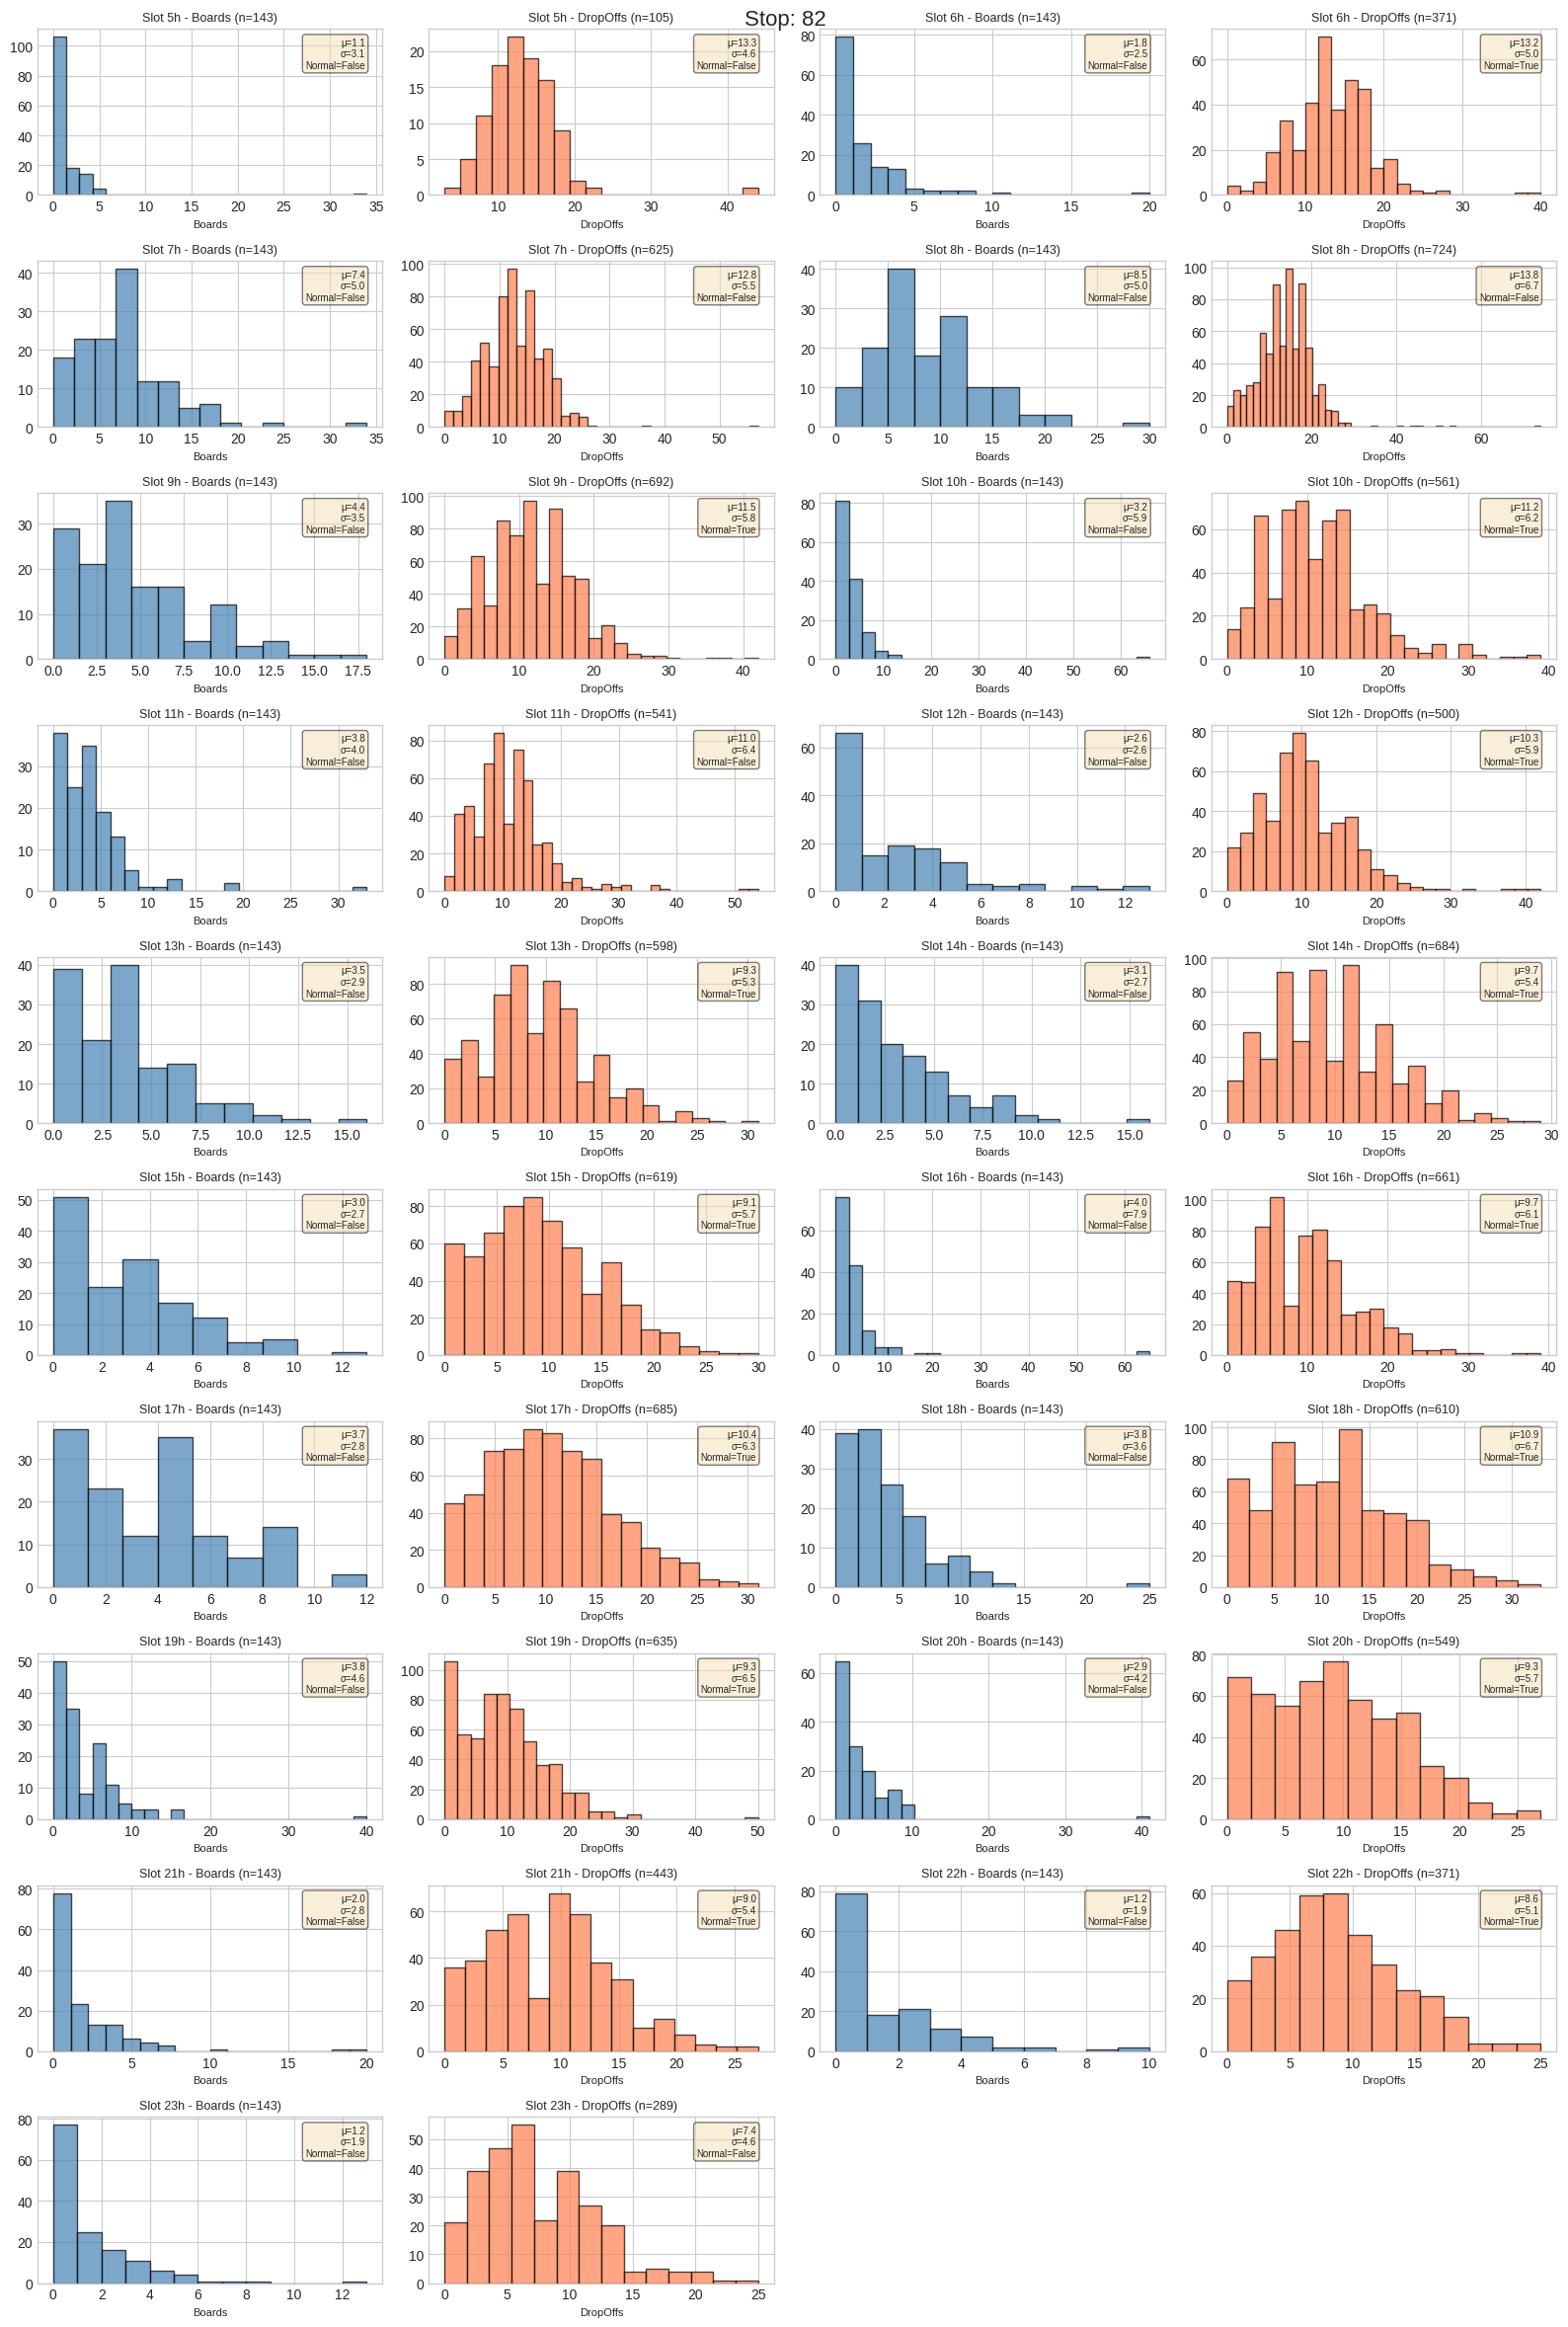





 Results obtained, for stop 562:  
	Percentage of Normal Boards : 57.89%
	Percentage of Normal DropOffs : 0.00%


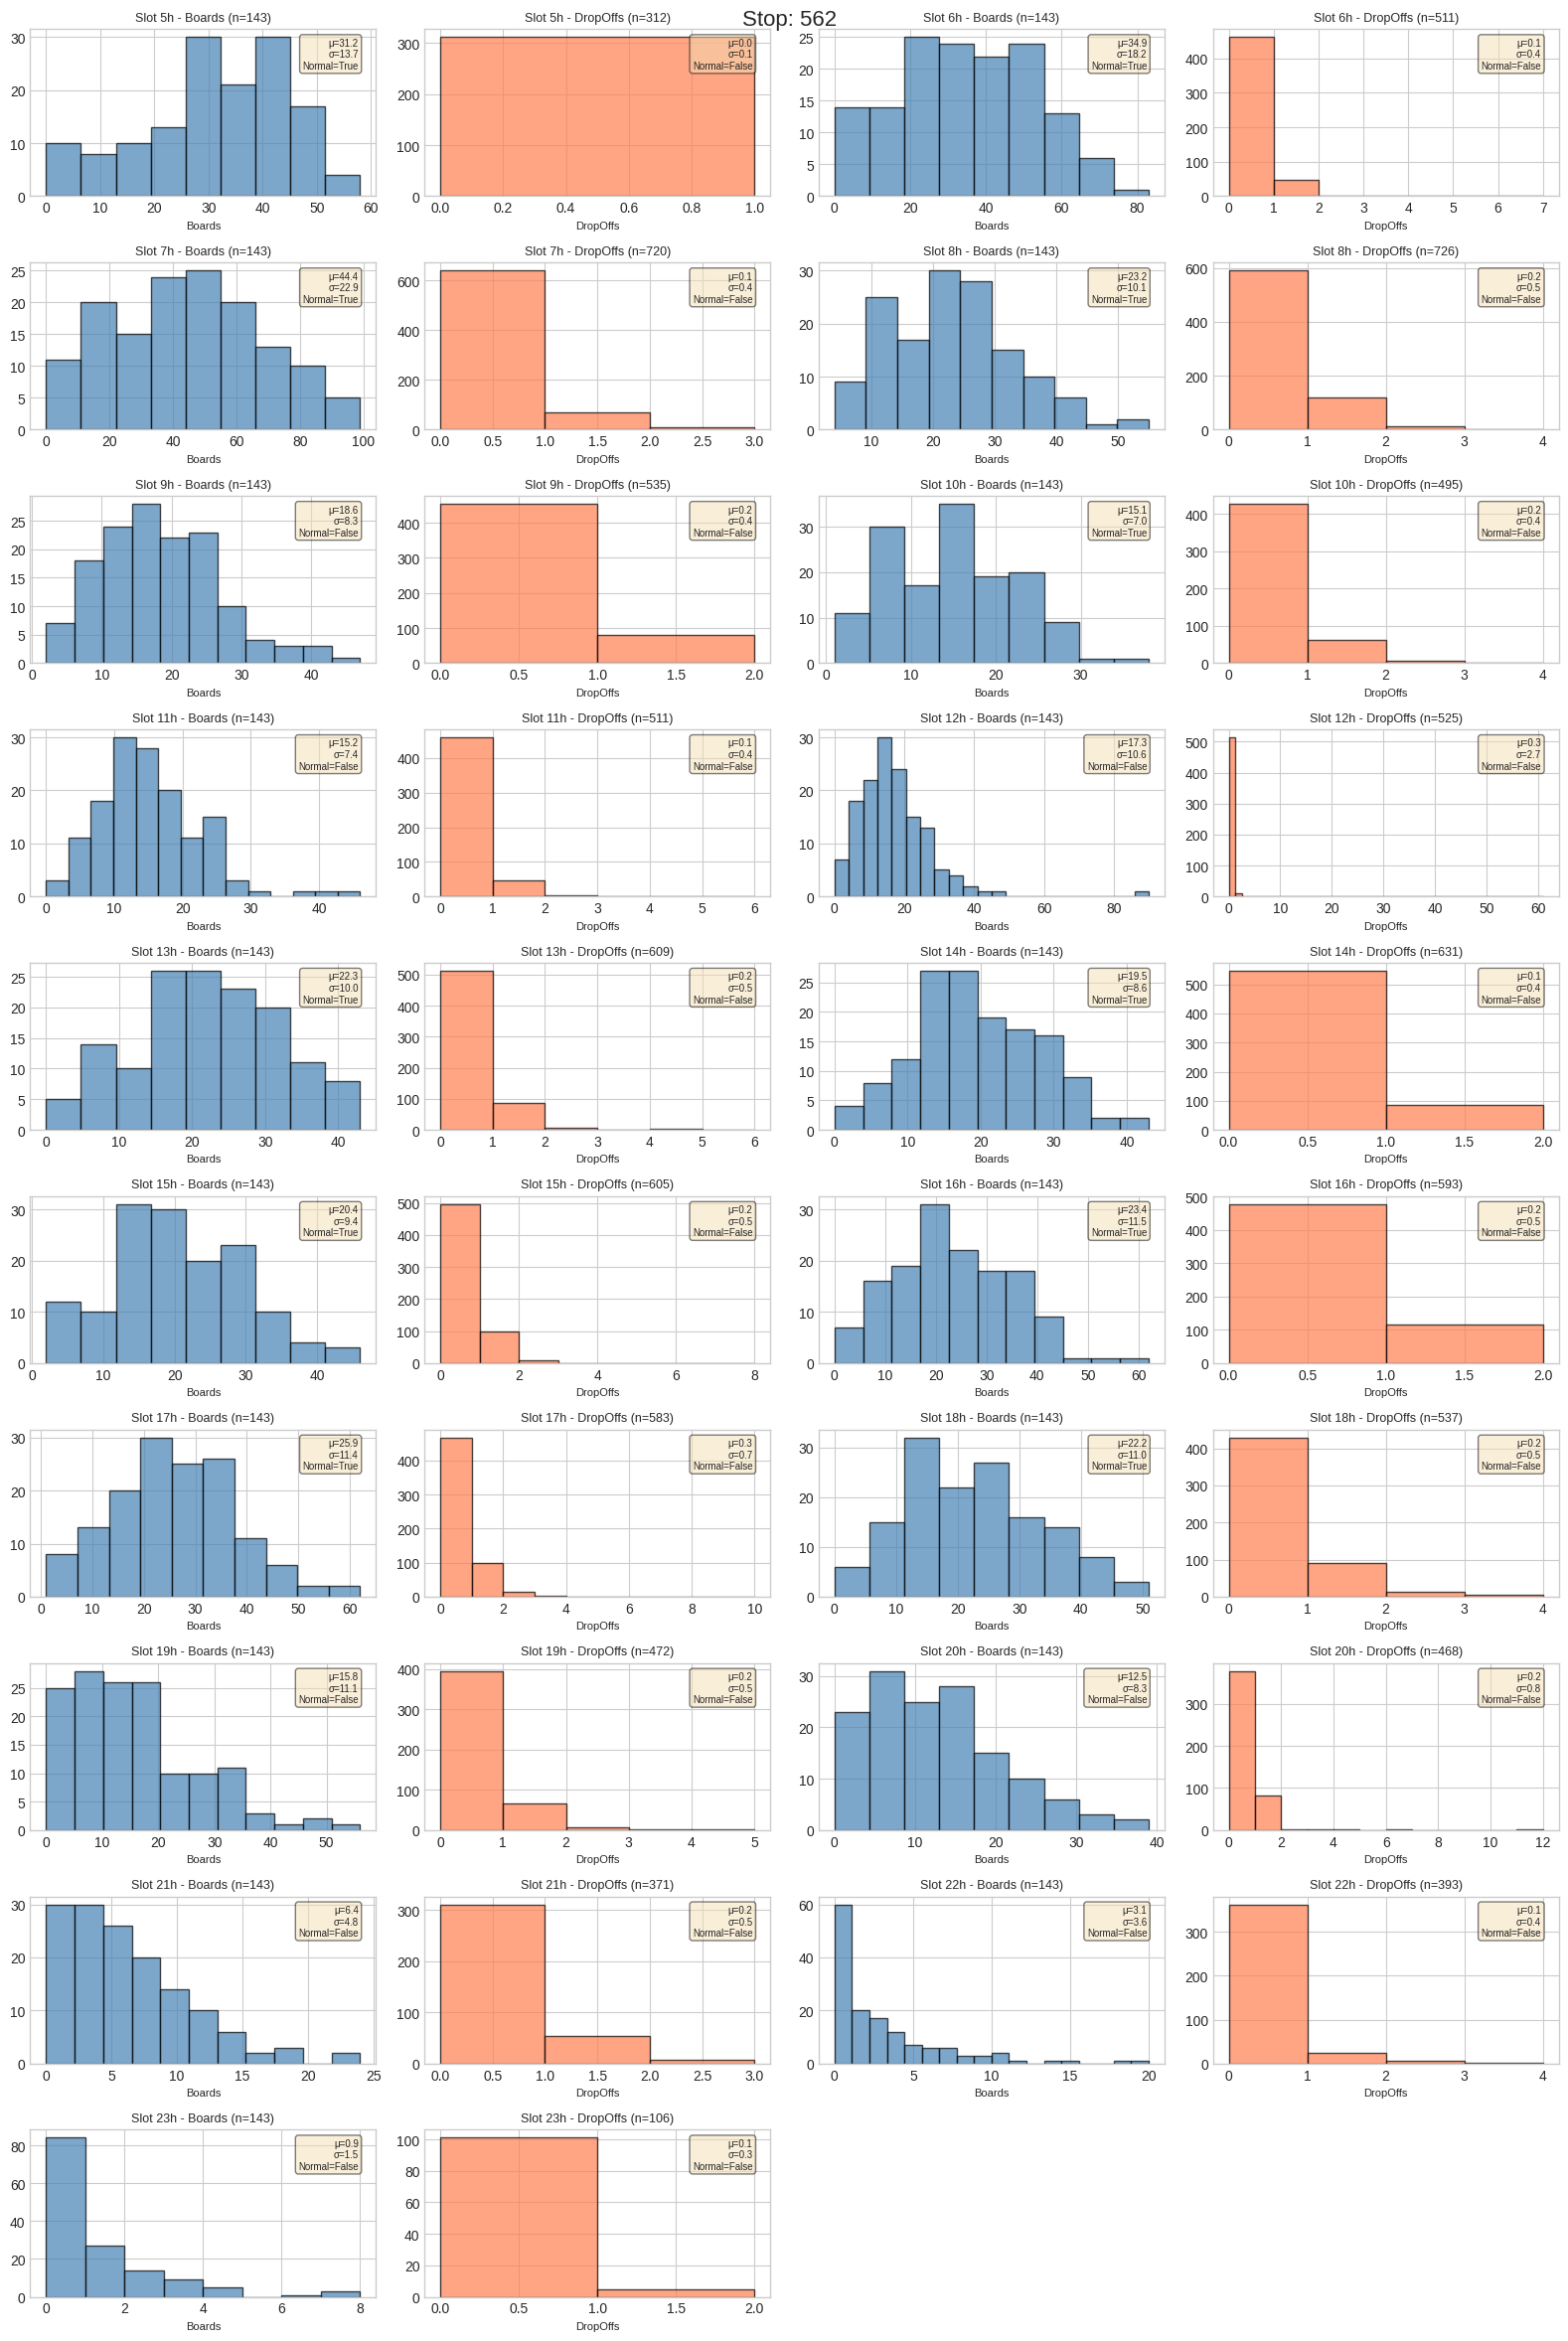





 Results obtained, for stop 3991:  
	Percentage of Normal Boards : 57.89%
	Percentage of Normal DropOffs : 31.58%


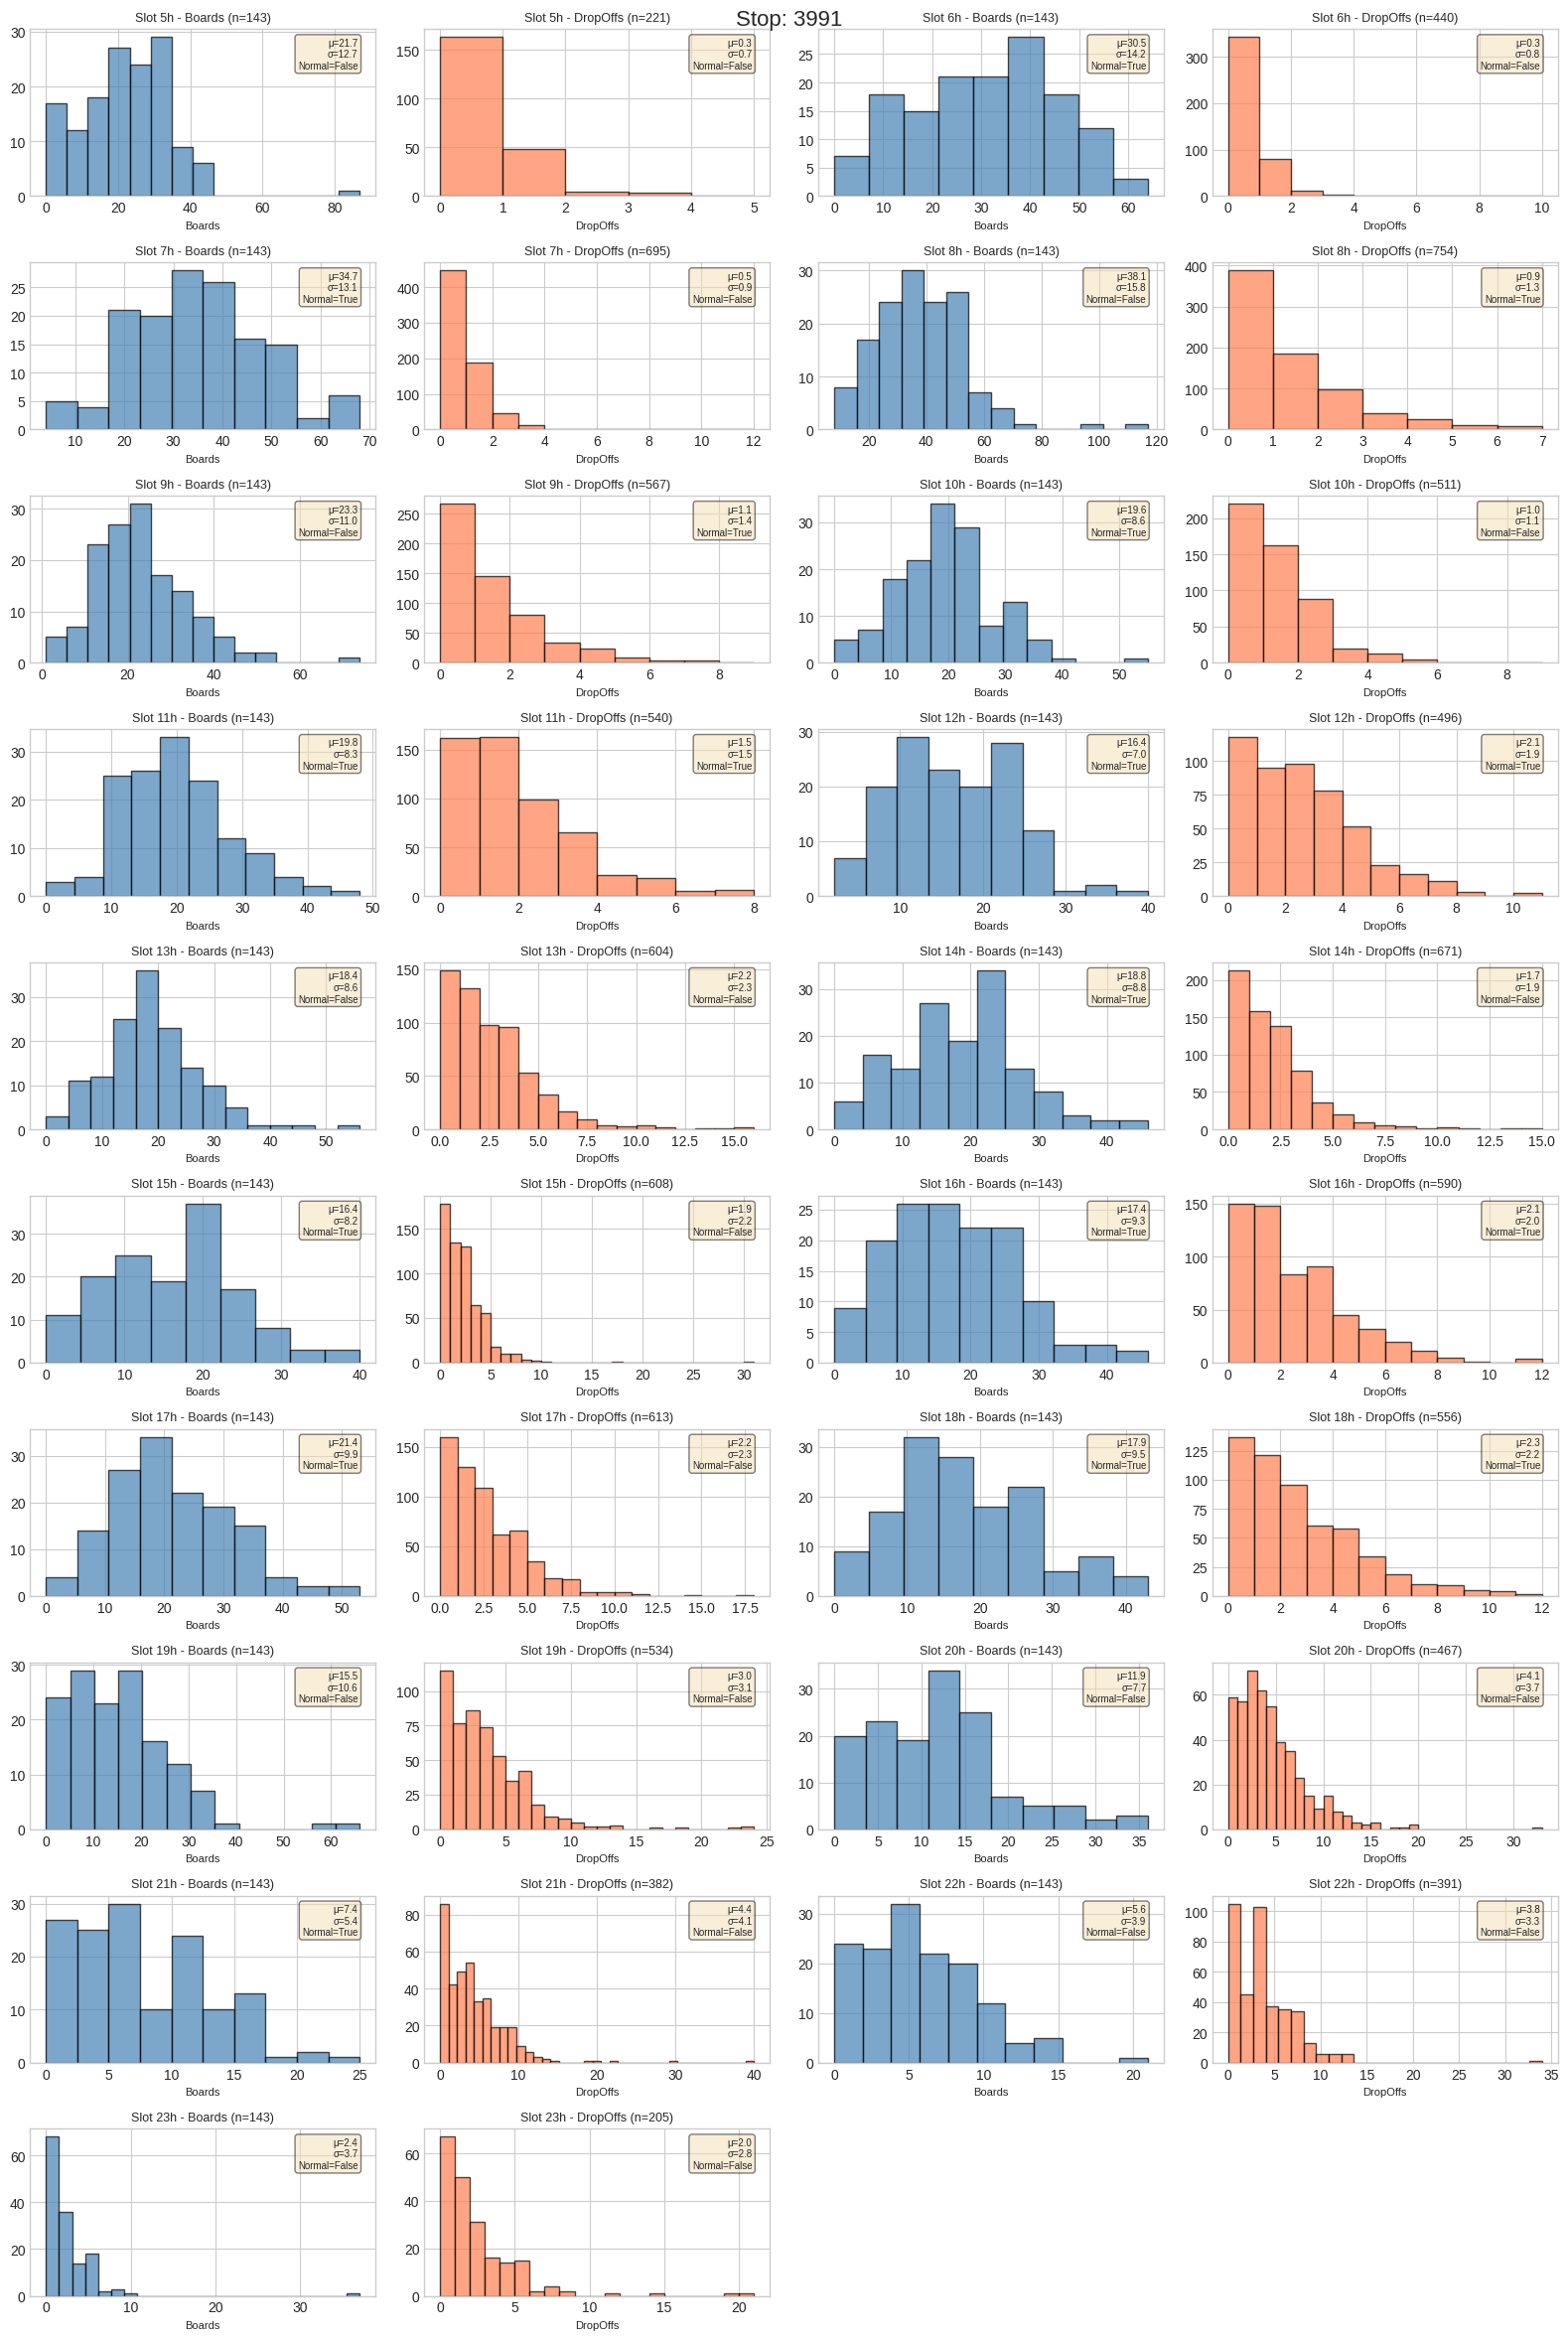





 Results obtained, for stop 4090:  
	Percentage of Normal Boards : 68.42%
	Percentage of Normal DropOffs : 10.53%


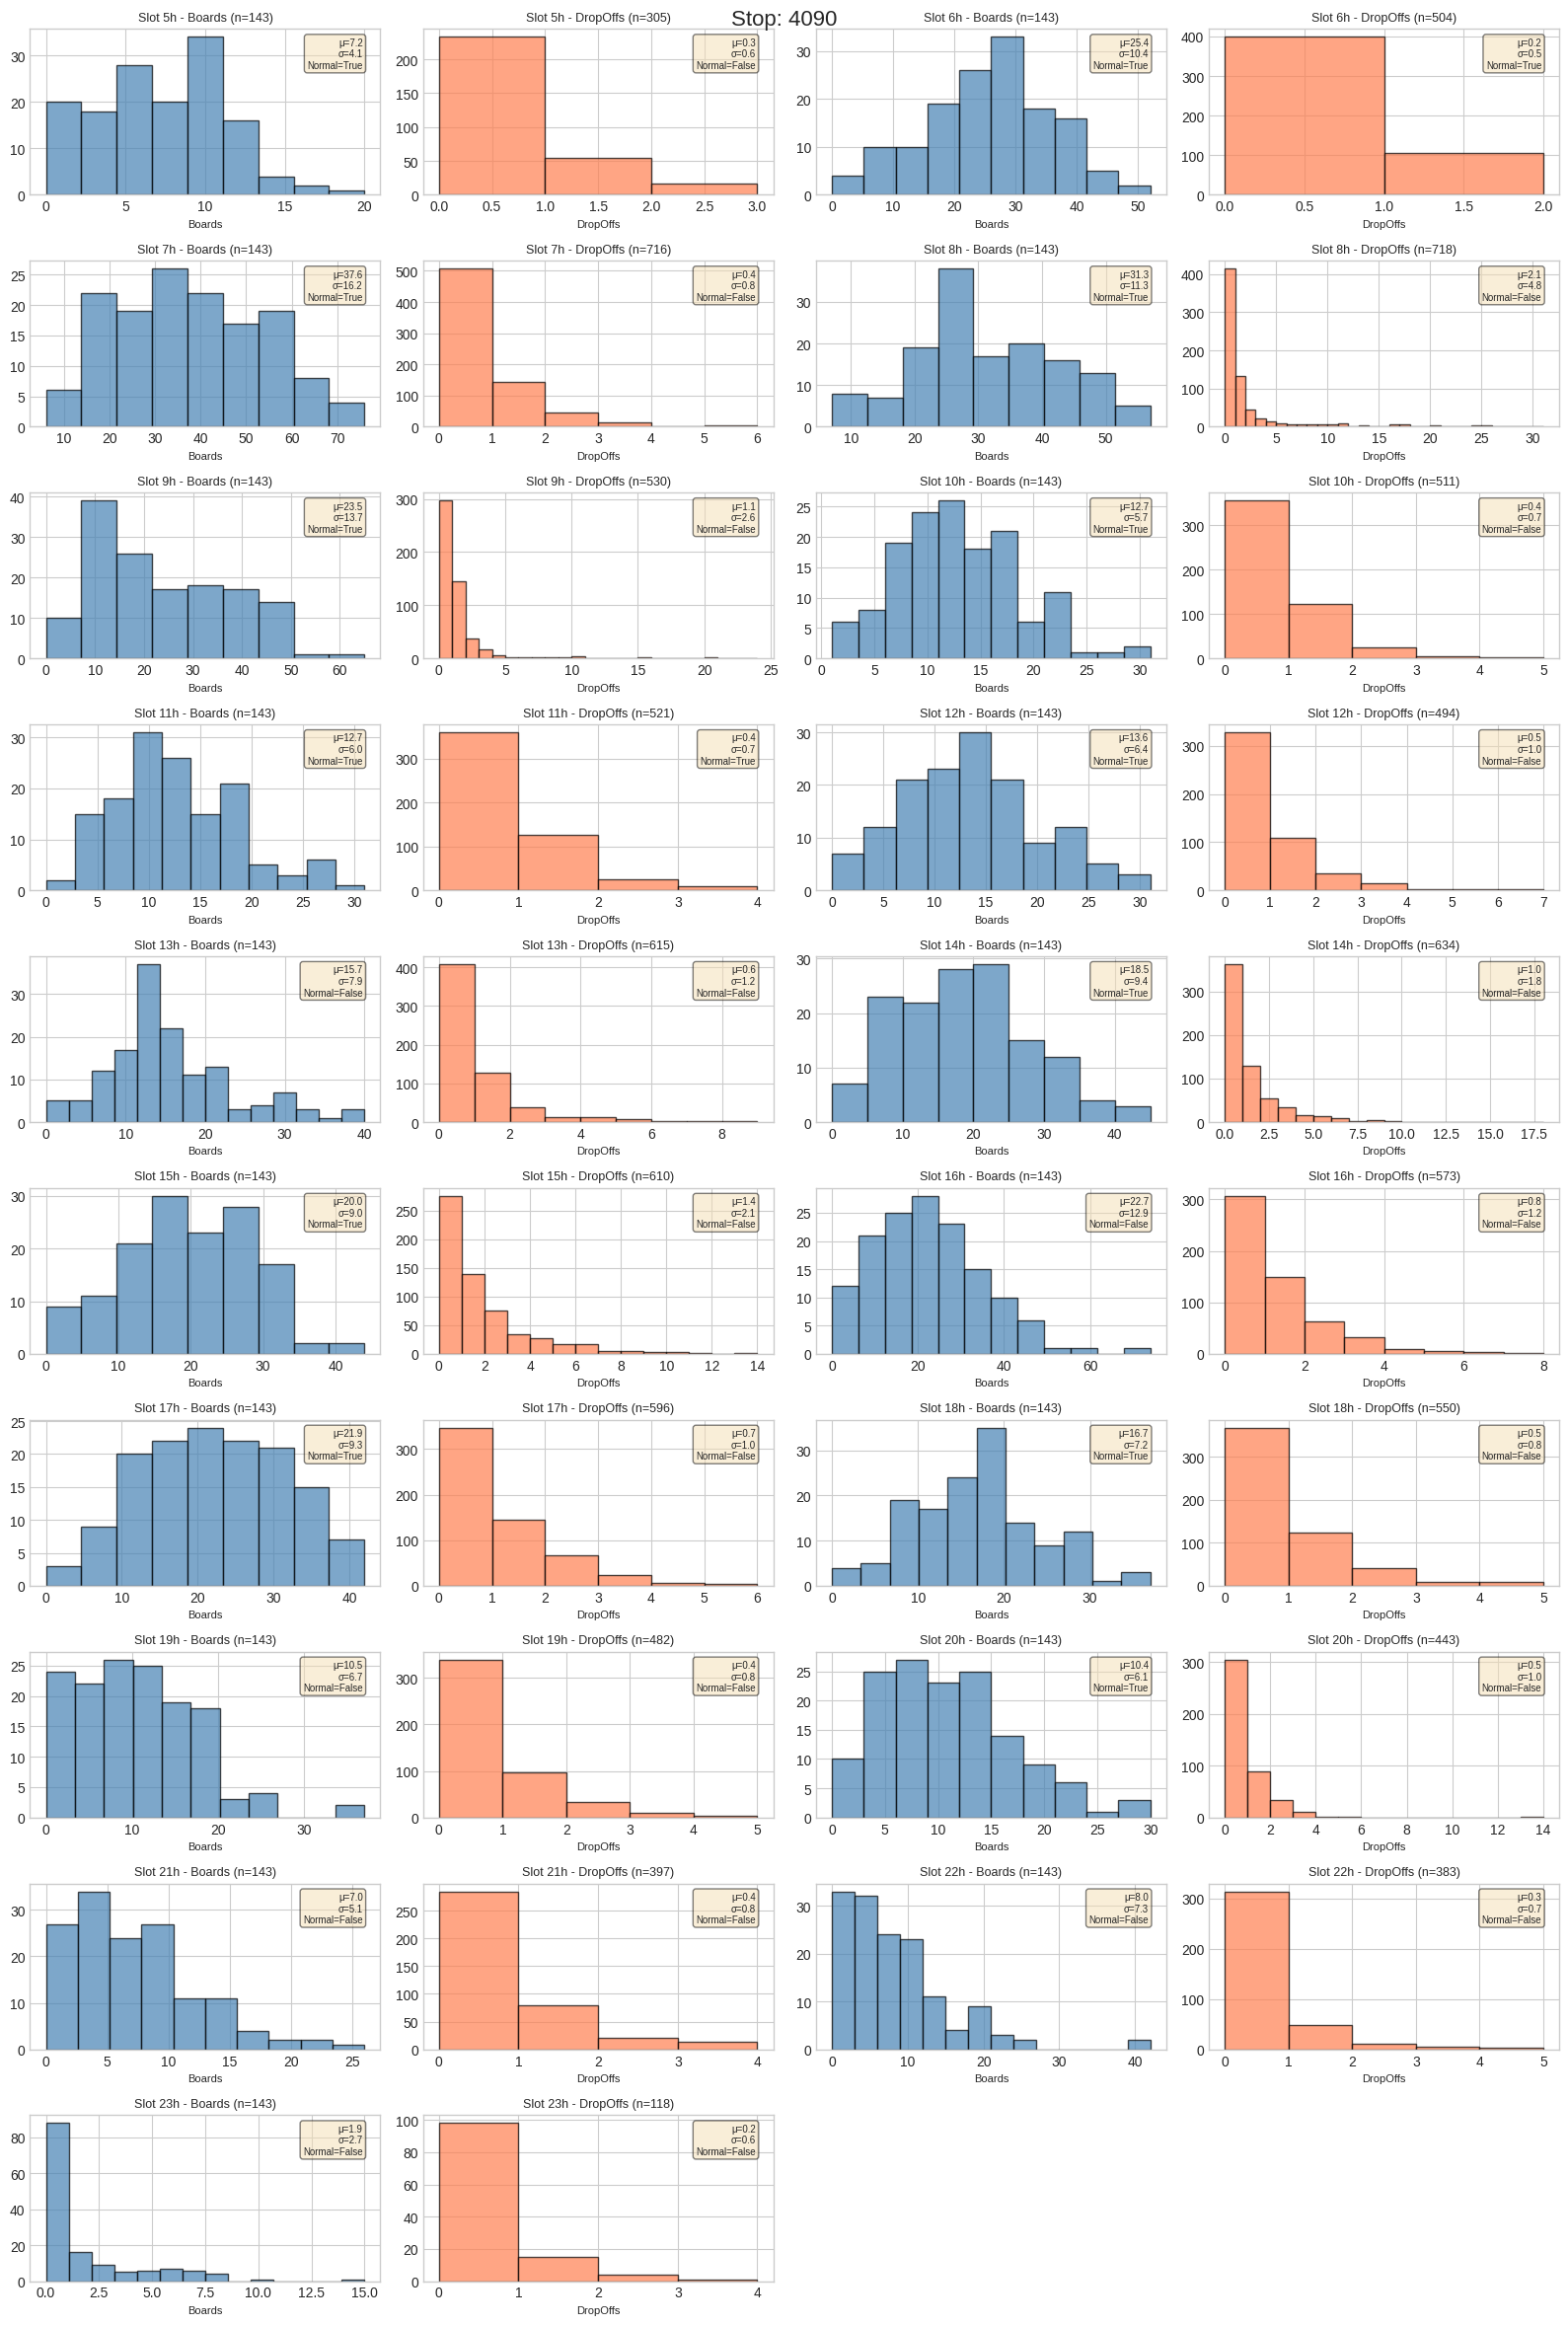





 Results obtained, for stop 3903:  
	Percentage of Normal Boards : 68.42%
	Percentage of Normal DropOffs : 84.21%


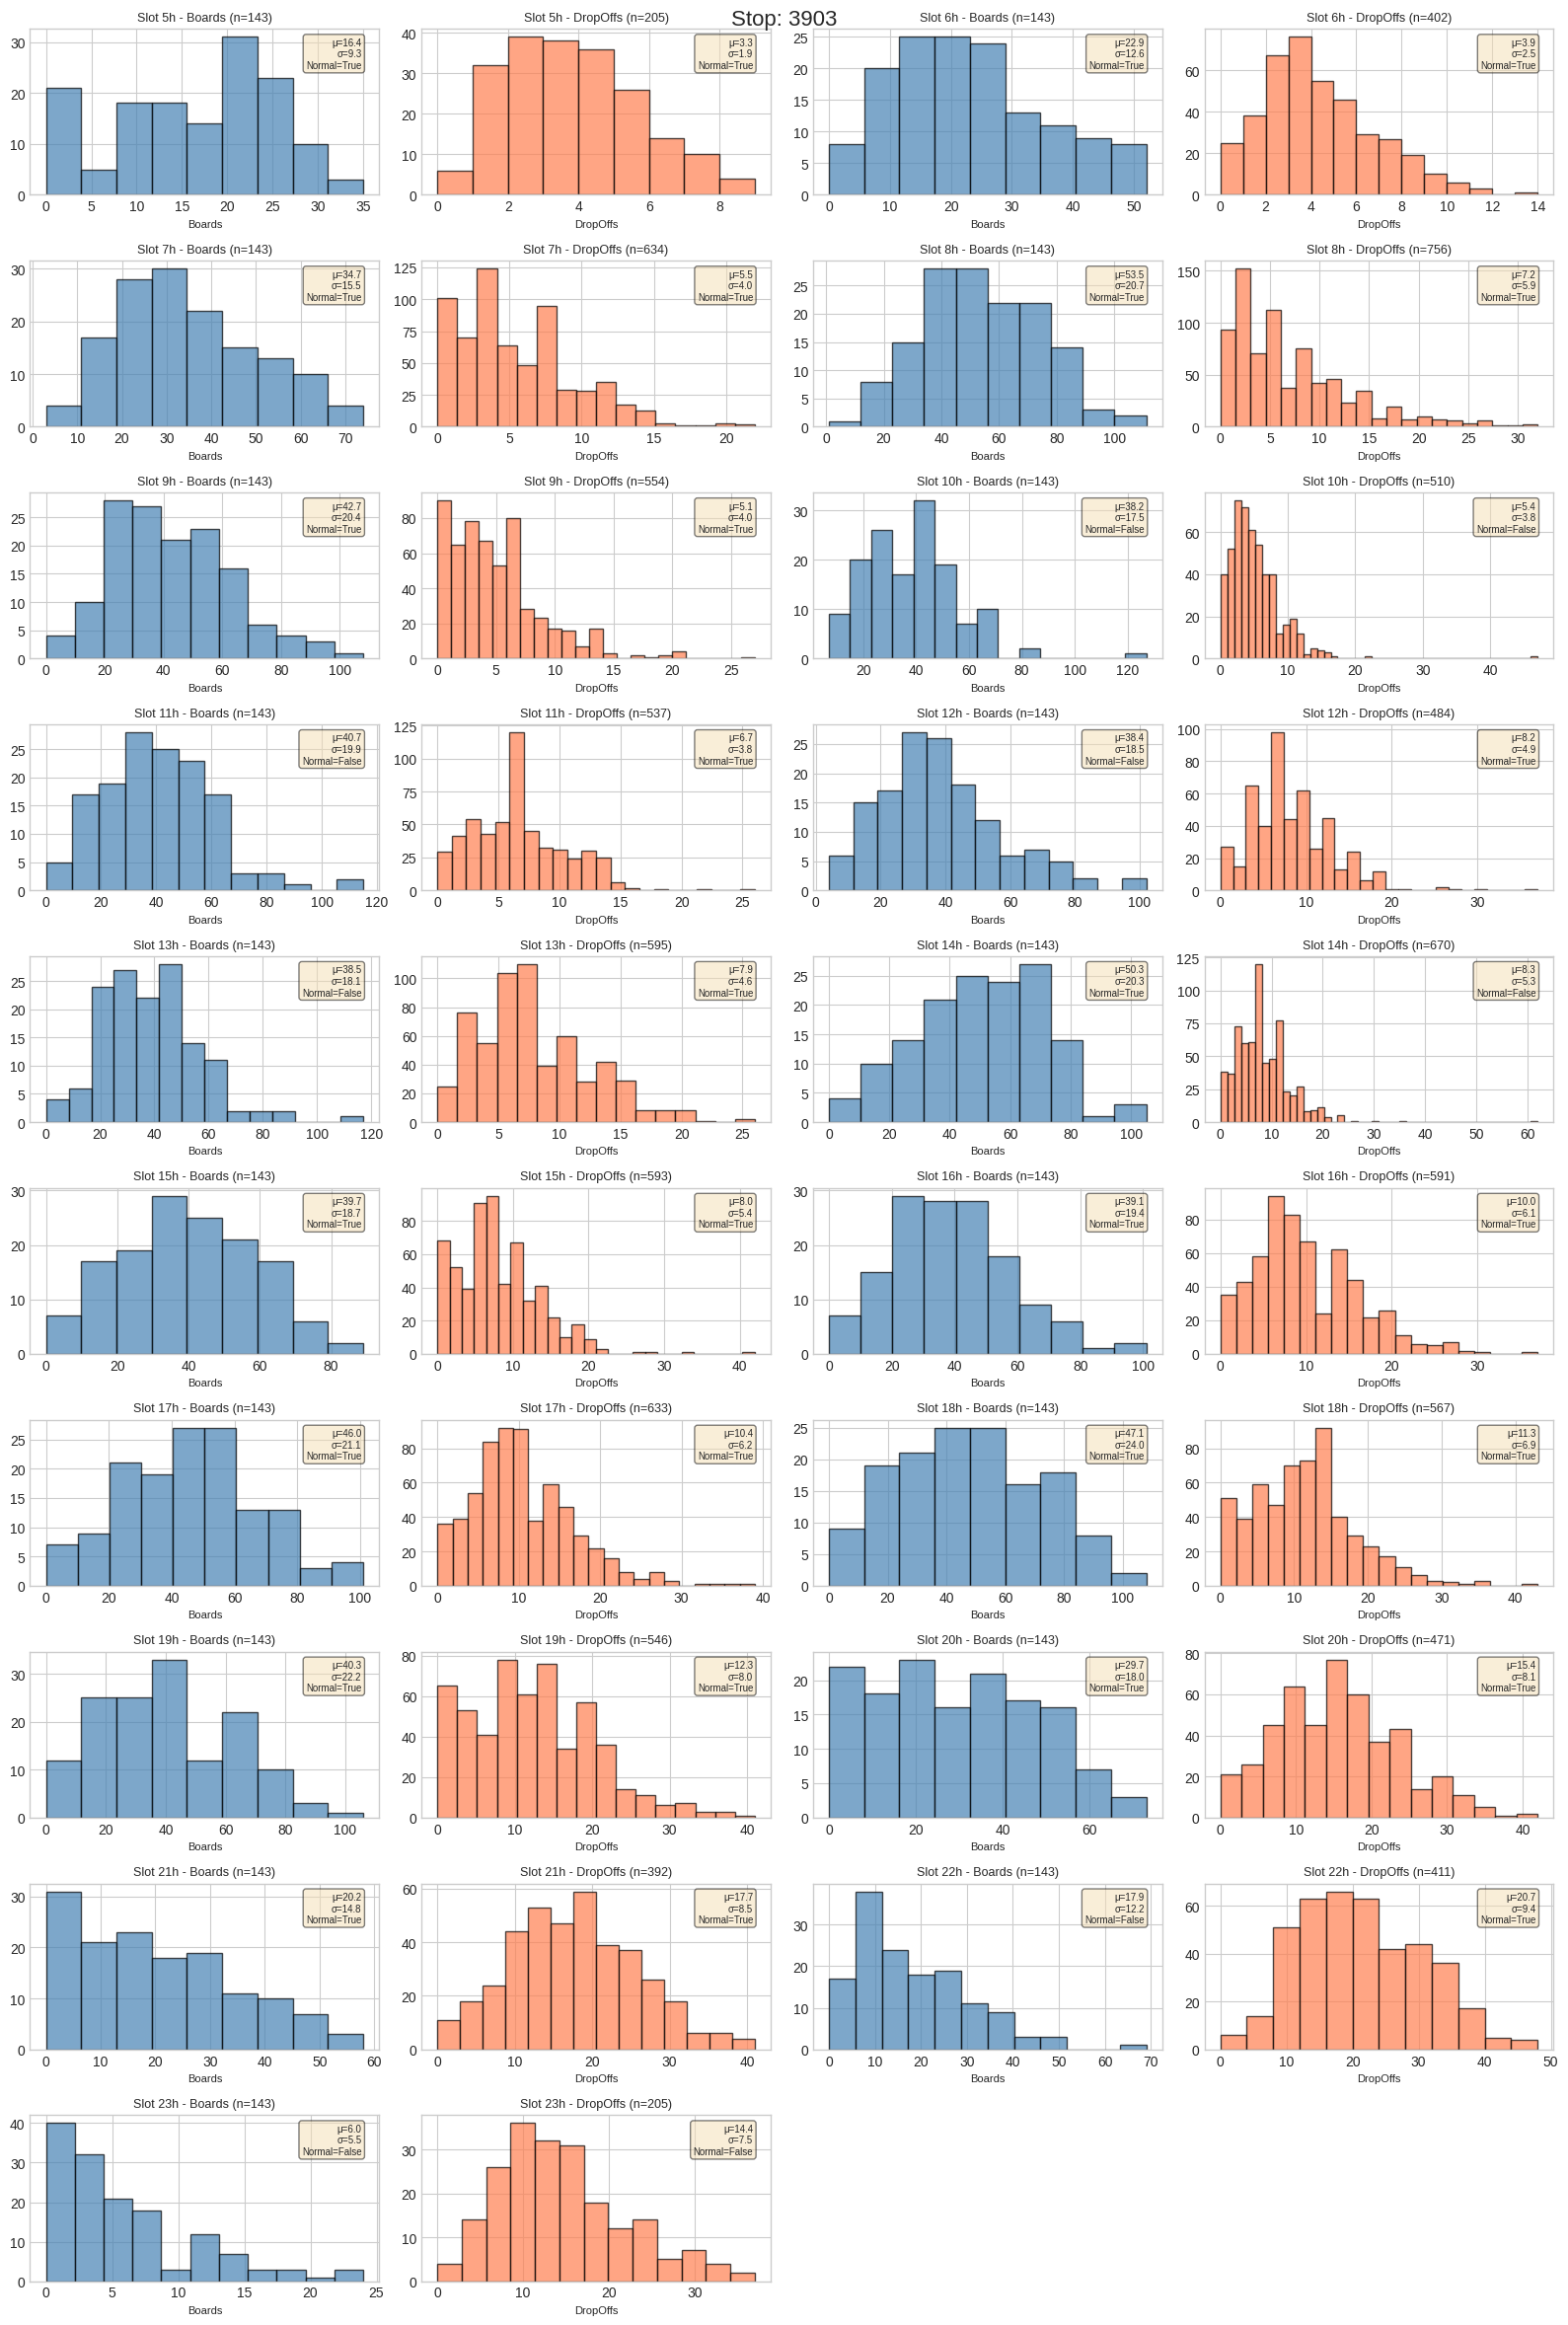





 Results obtained, for stop 5939:  
	Percentage of Normal Boards : 47.37%
	Percentage of Normal DropOffs : 0.00%


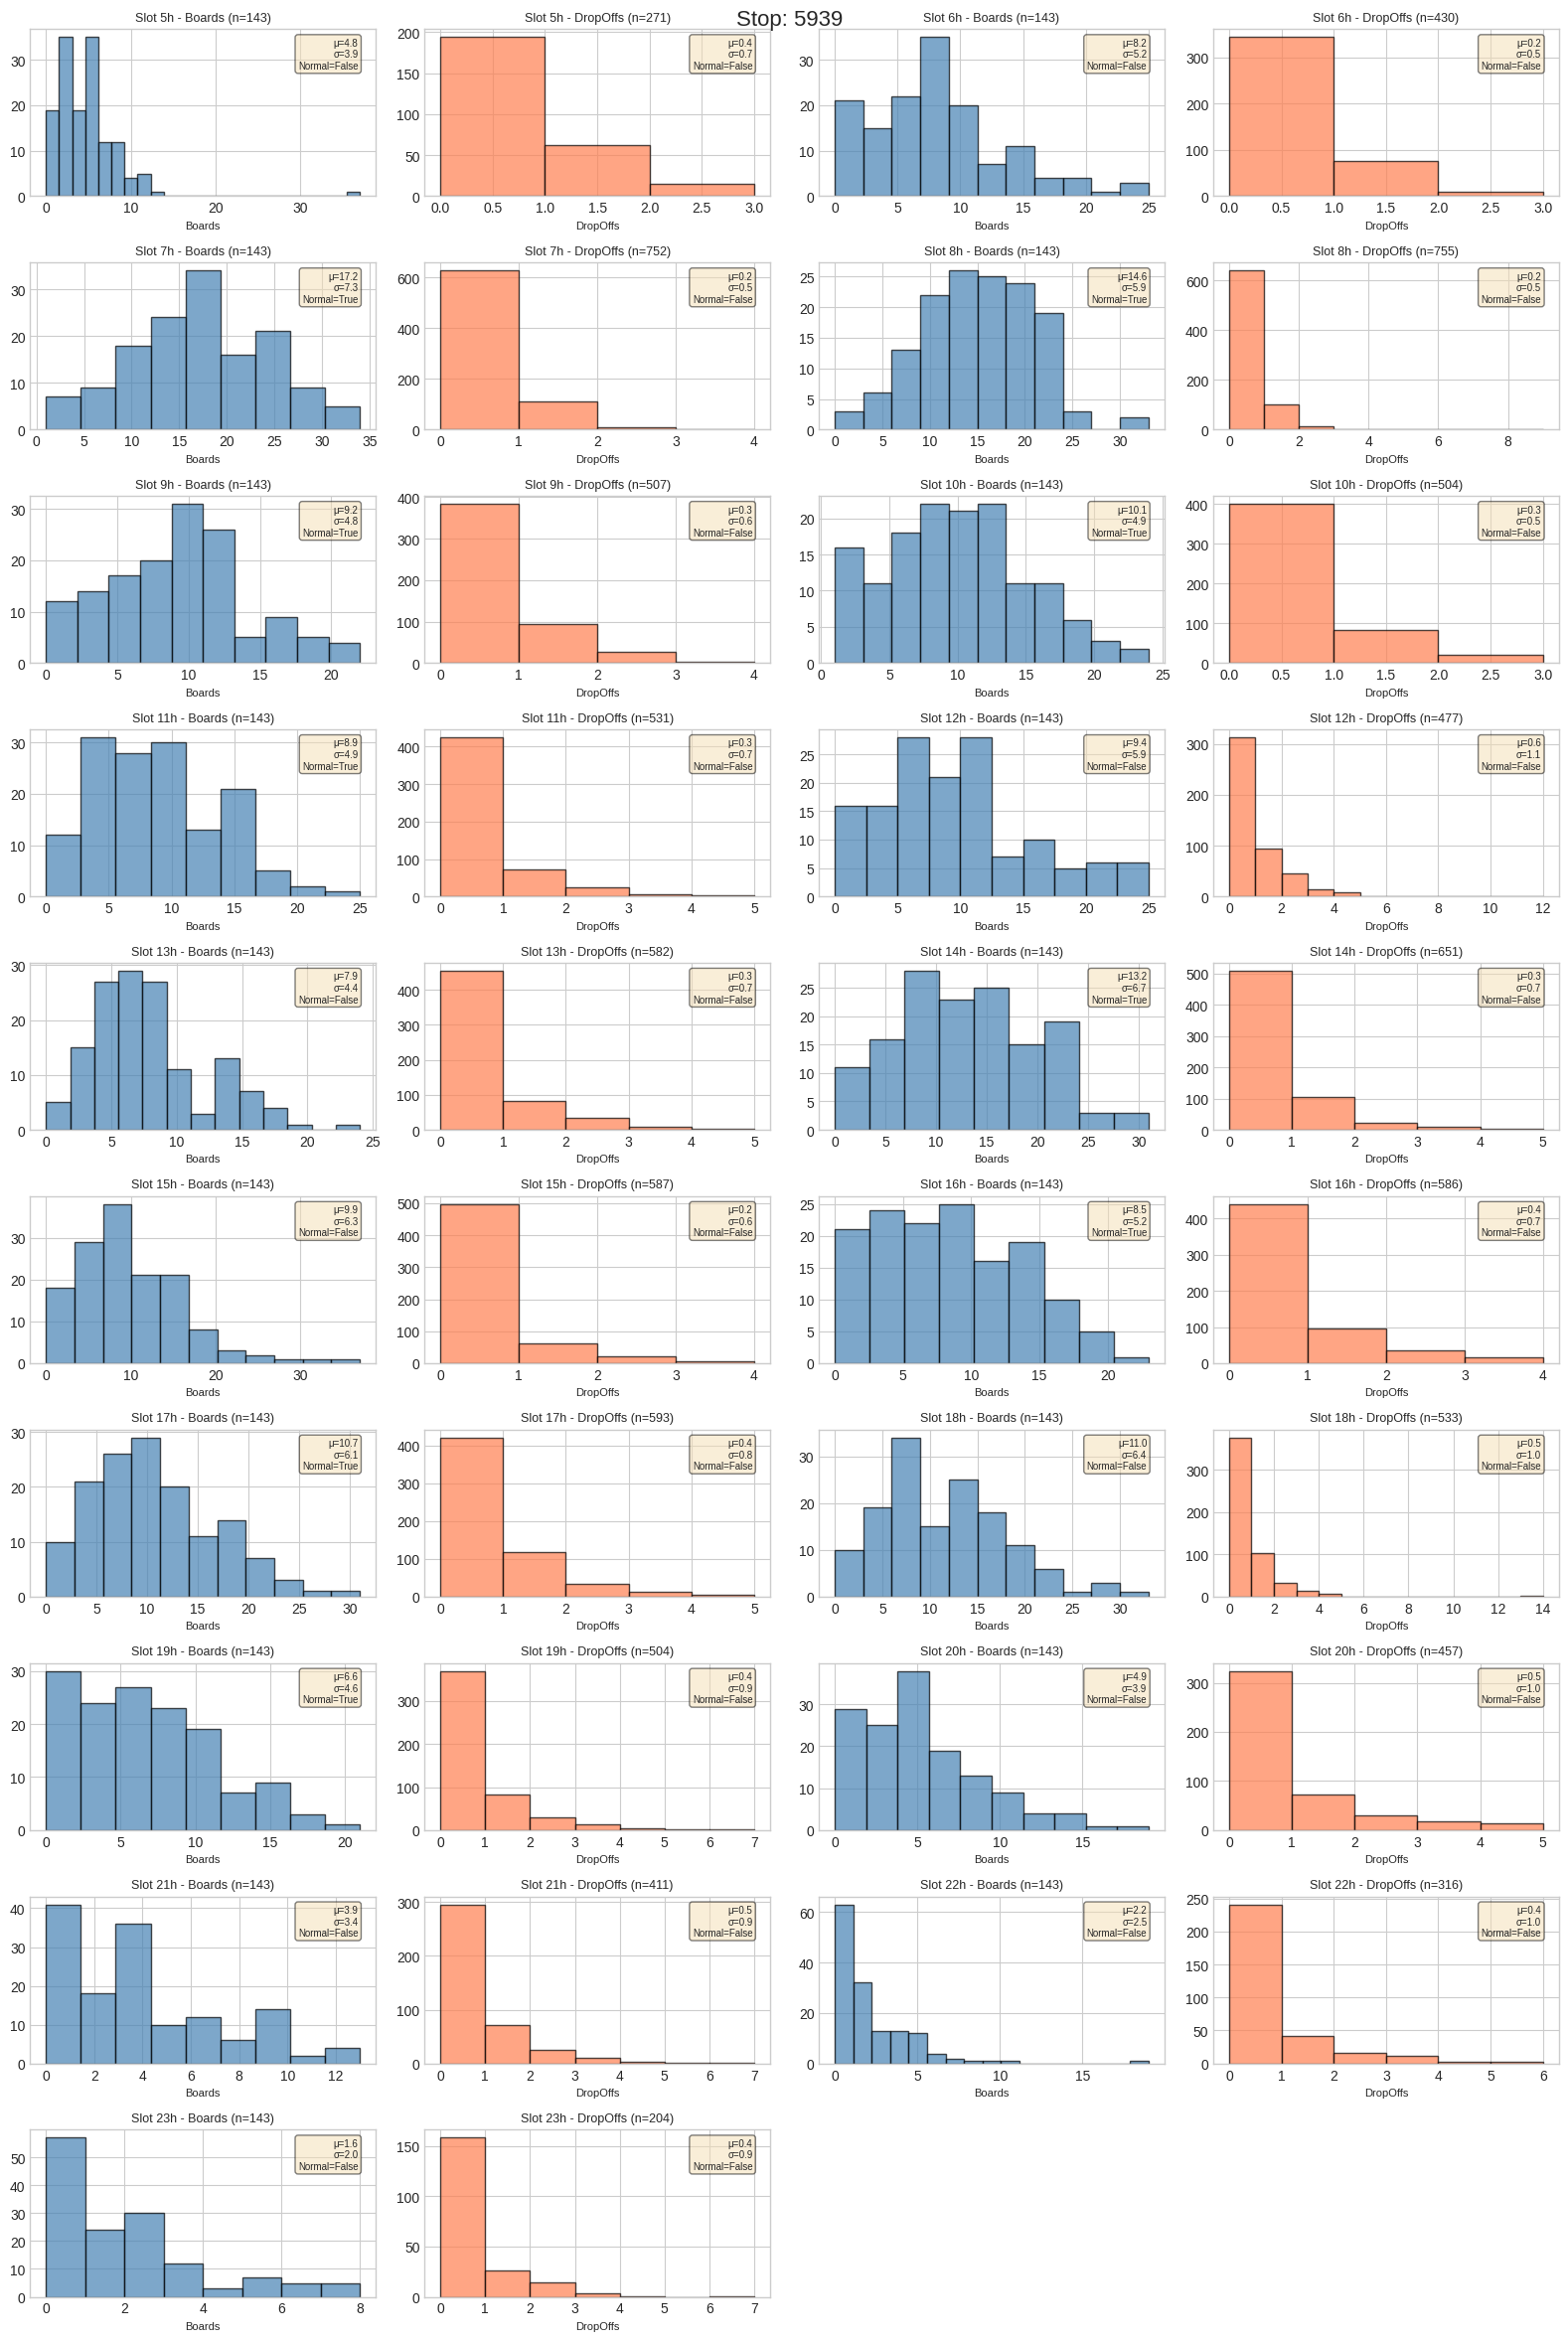





 Results obtained, for stop 4032:  
	Percentage of Normal Boards : 15.79%
	Percentage of Normal DropOffs : 63.16%


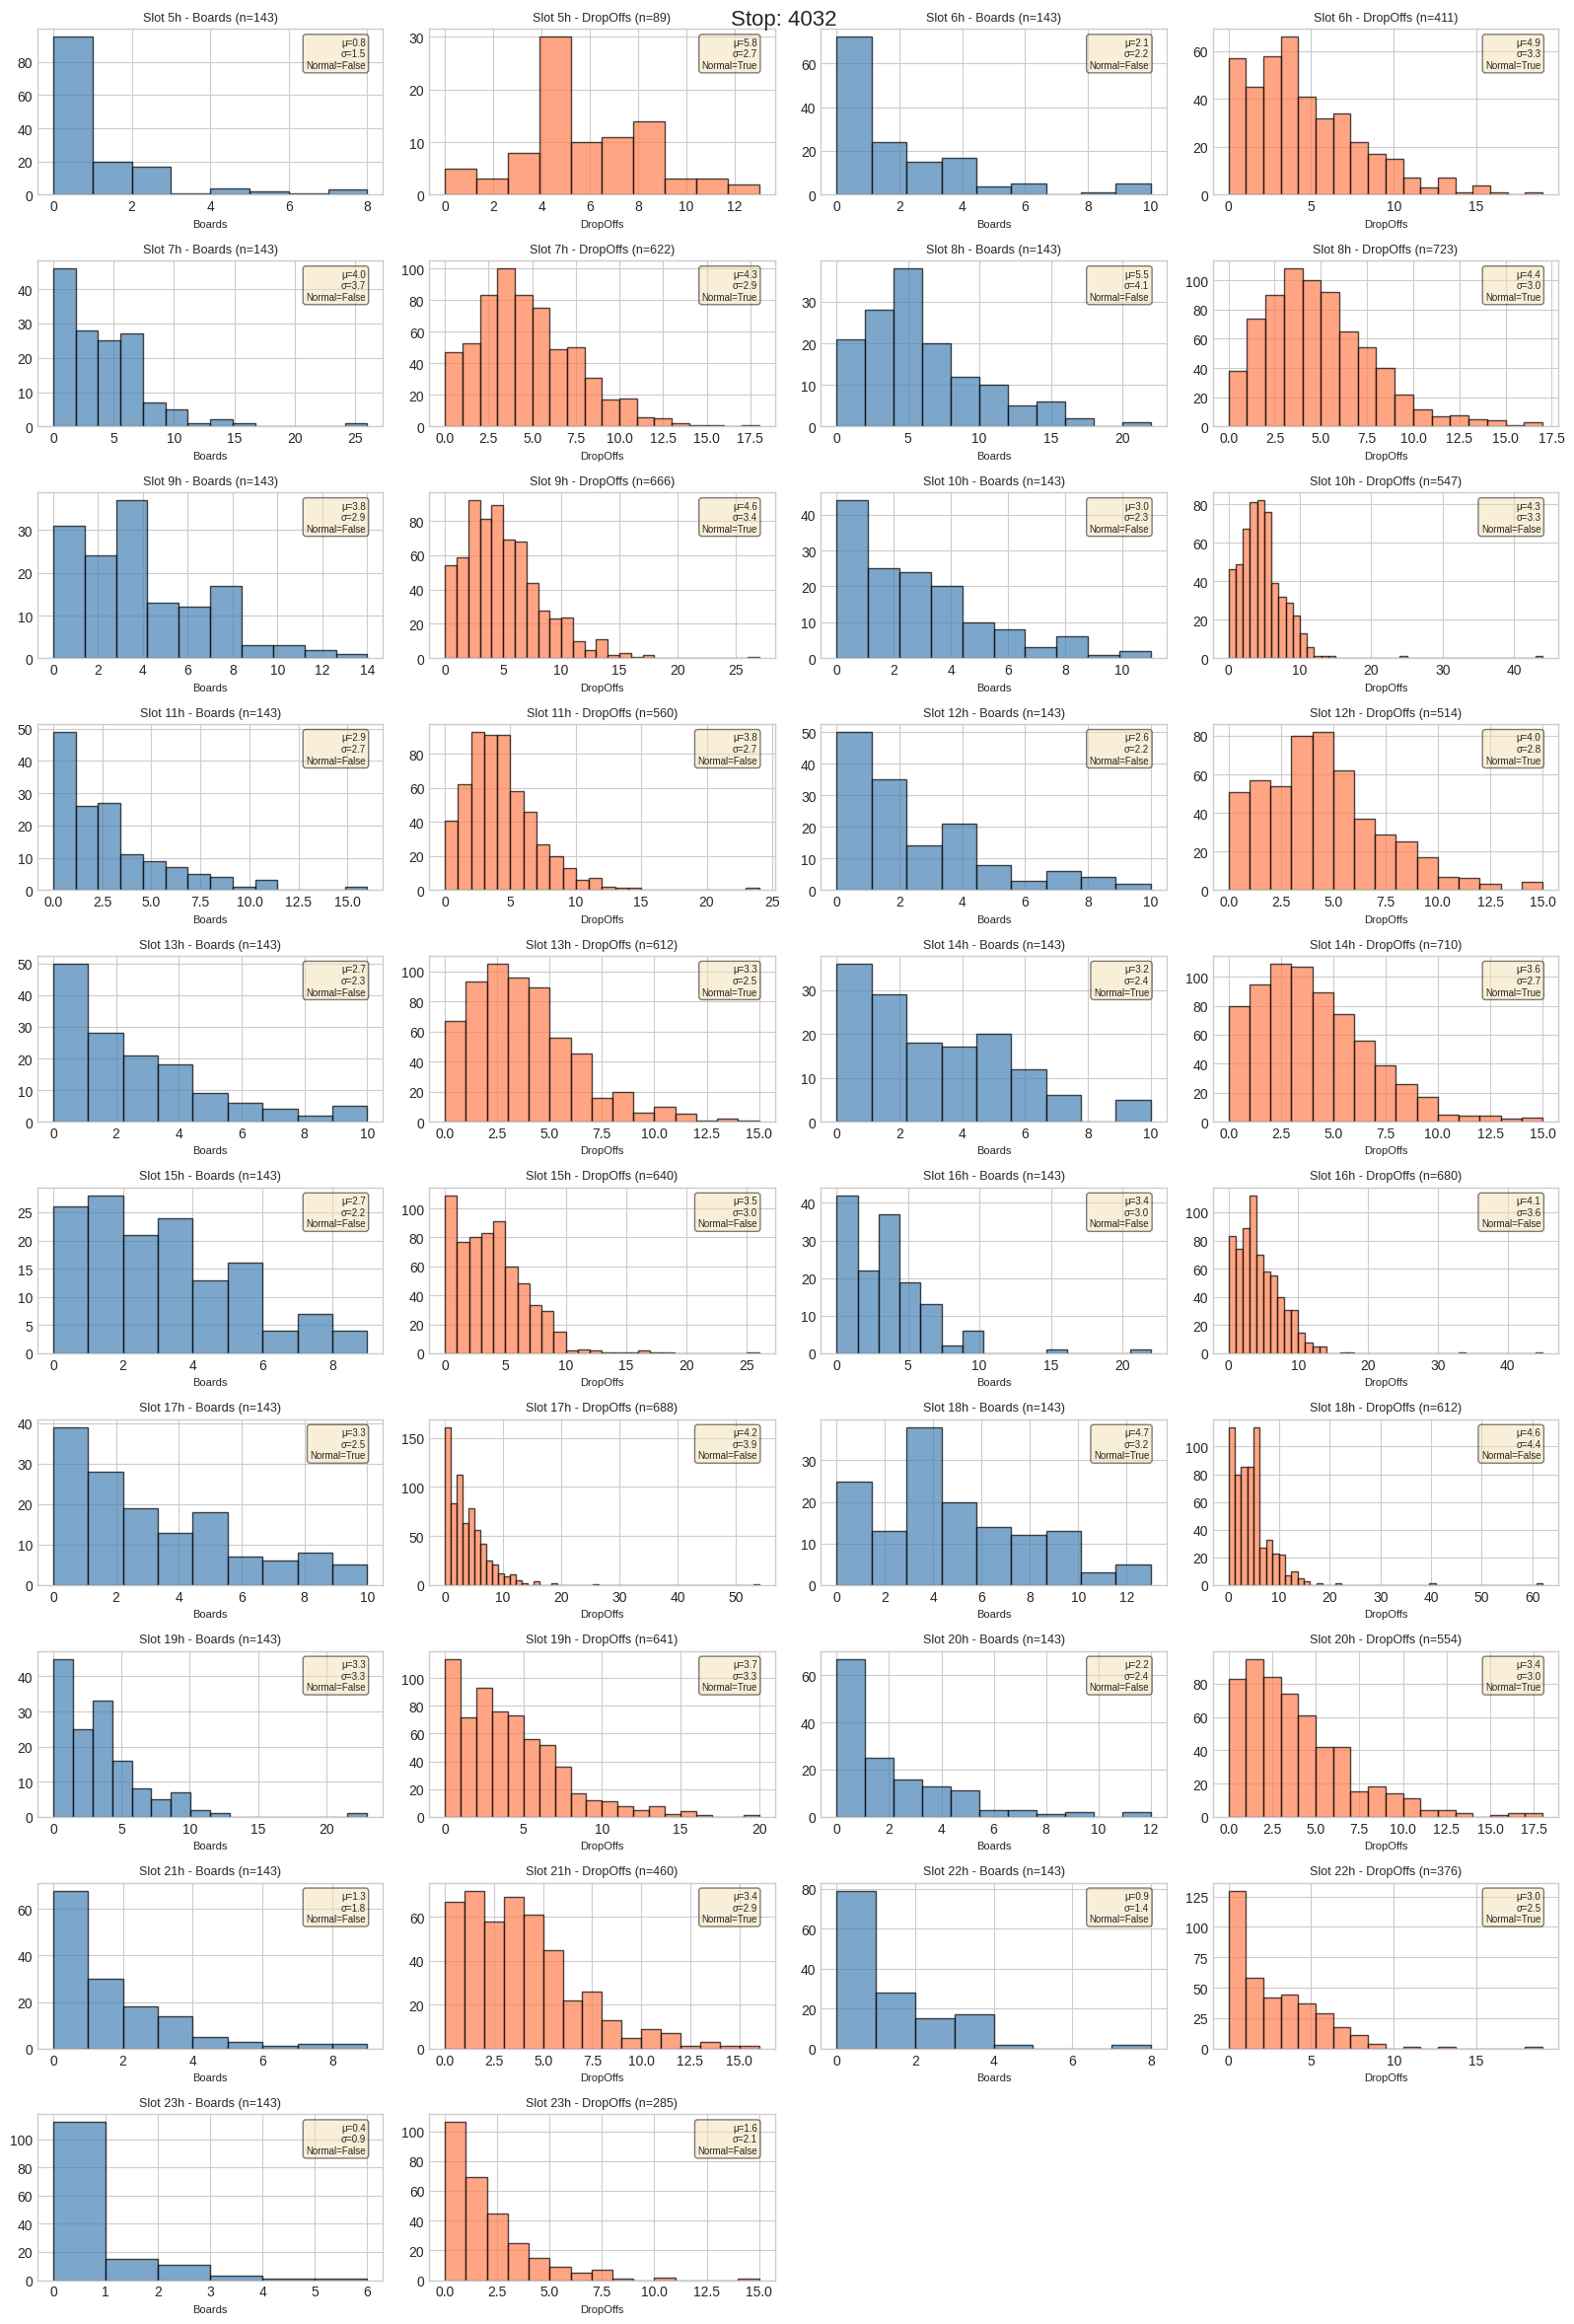





 Results obtained, for stop 1929:  
	Percentage of Normal Boards : 42.11%
	Percentage of Normal DropOffs : 68.42%


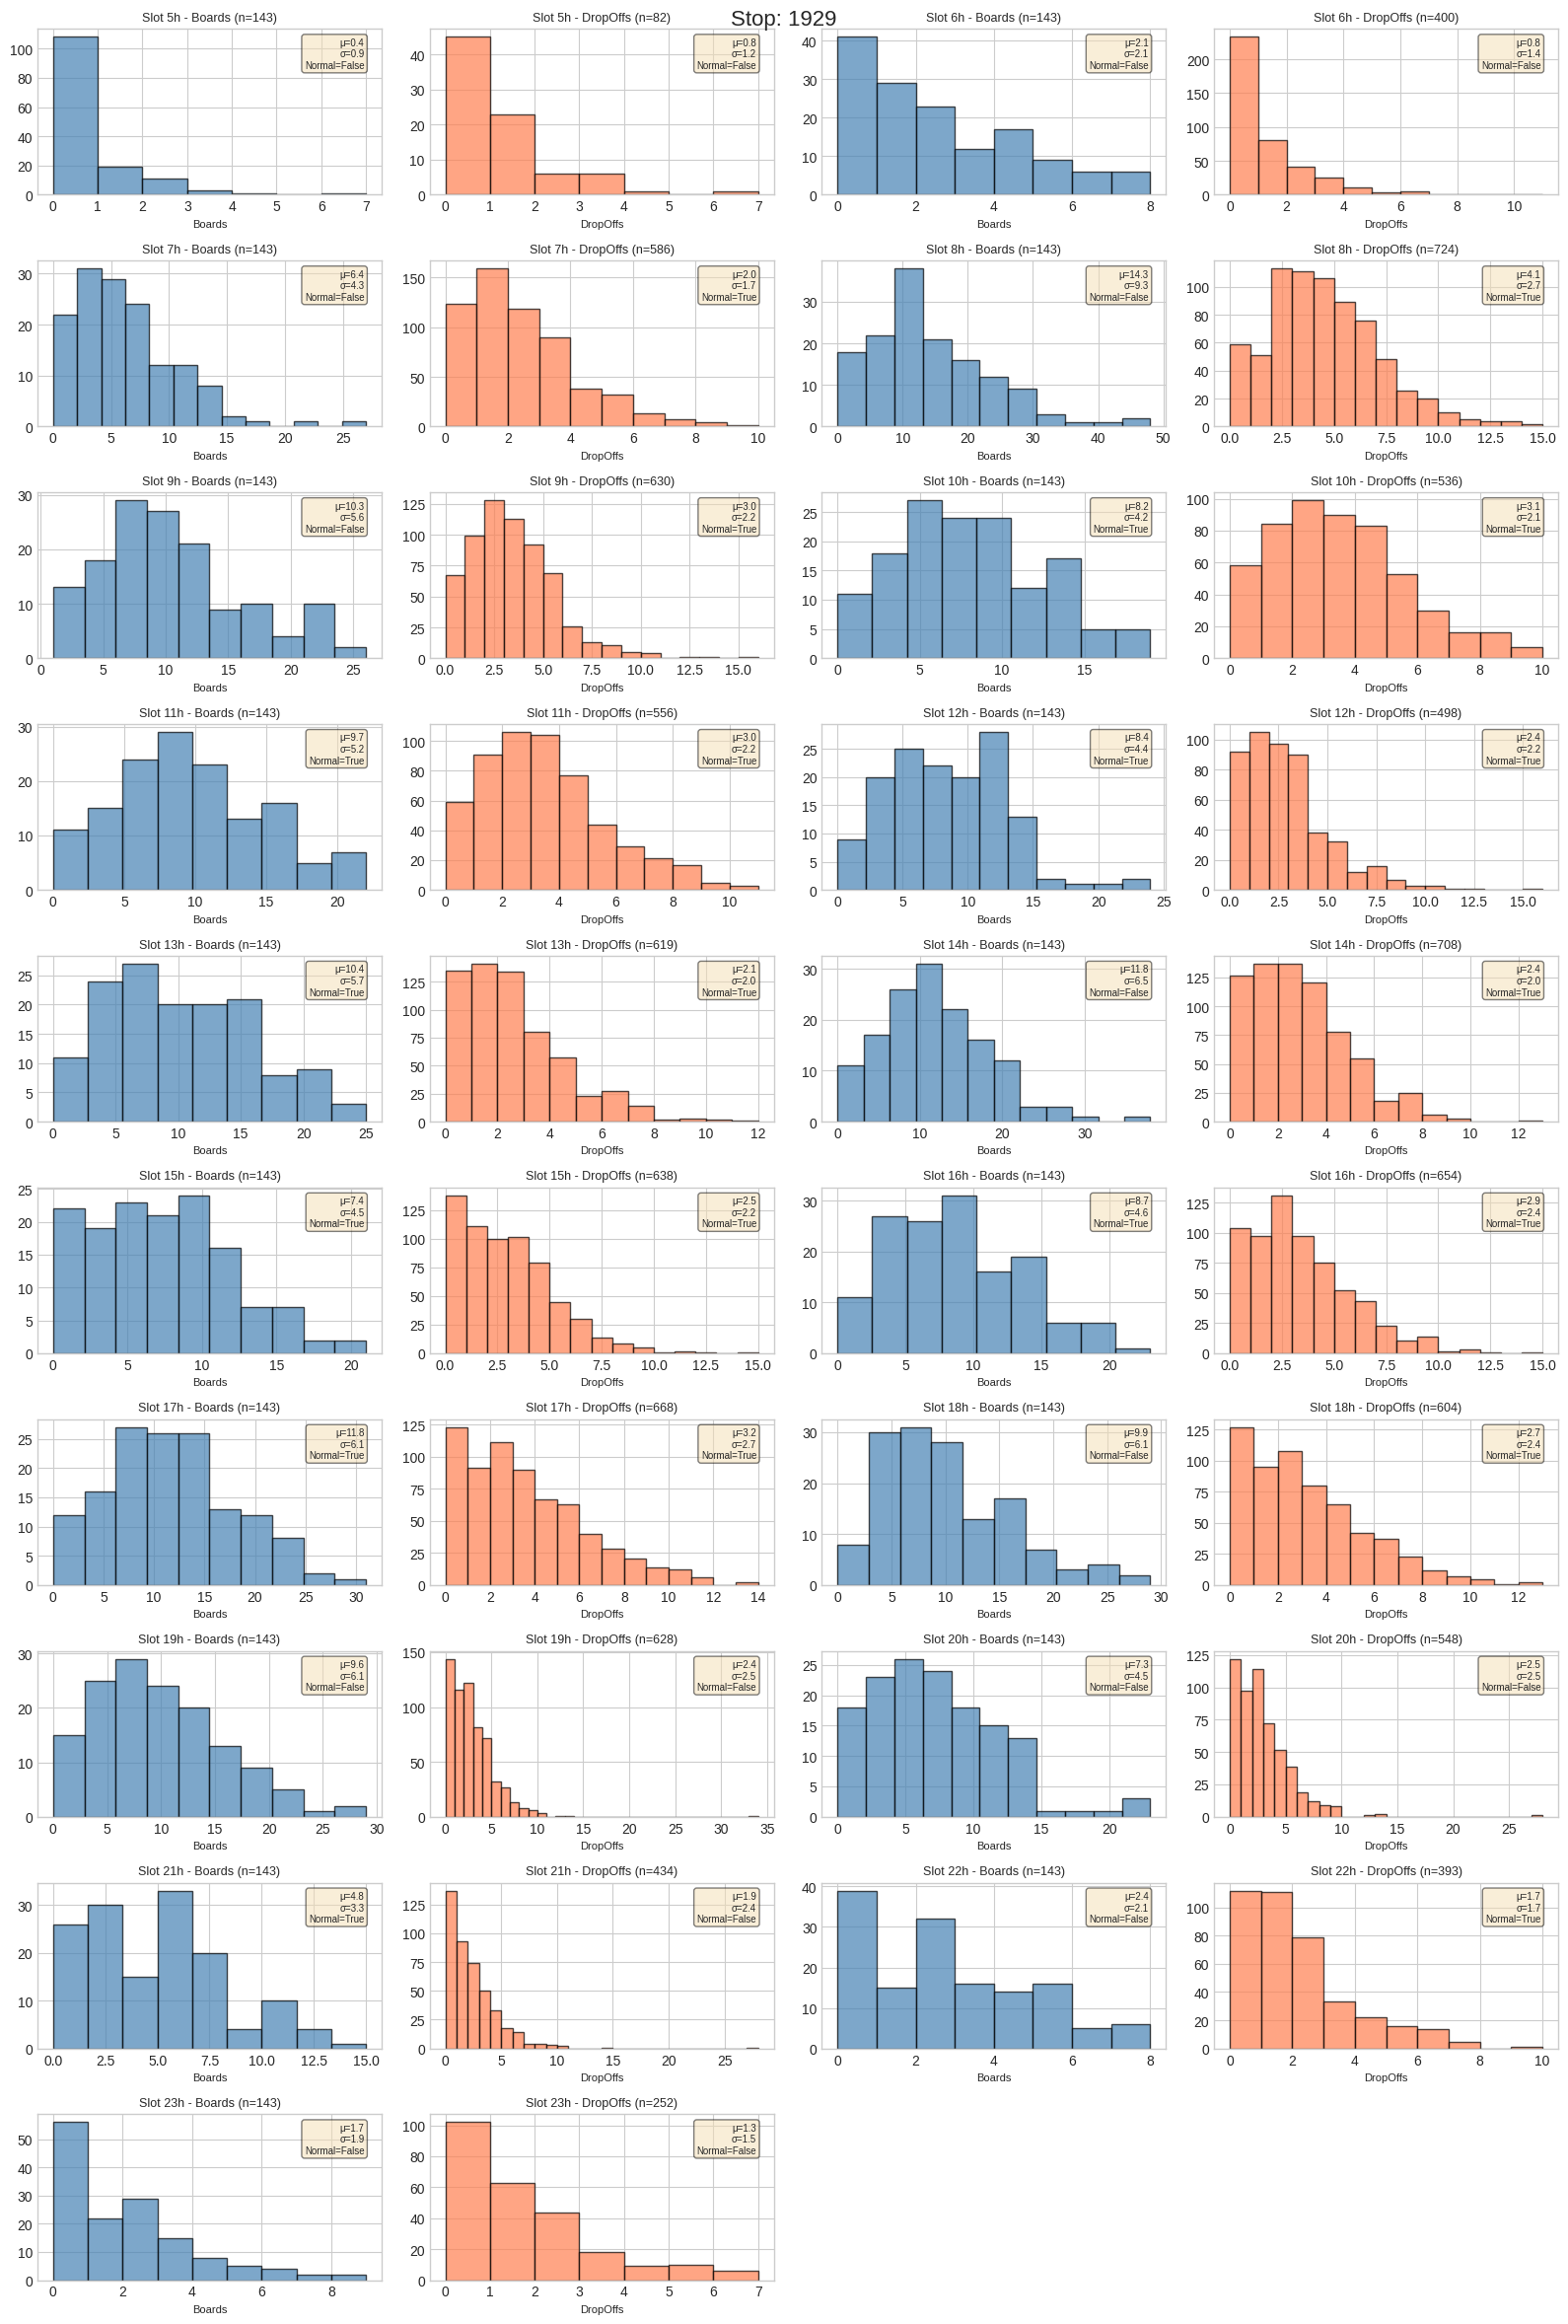





 Results obtained, for stop 4188:  
	Percentage of Normal Boards : 73.68%
	Percentage of Normal DropOffs : 68.42%


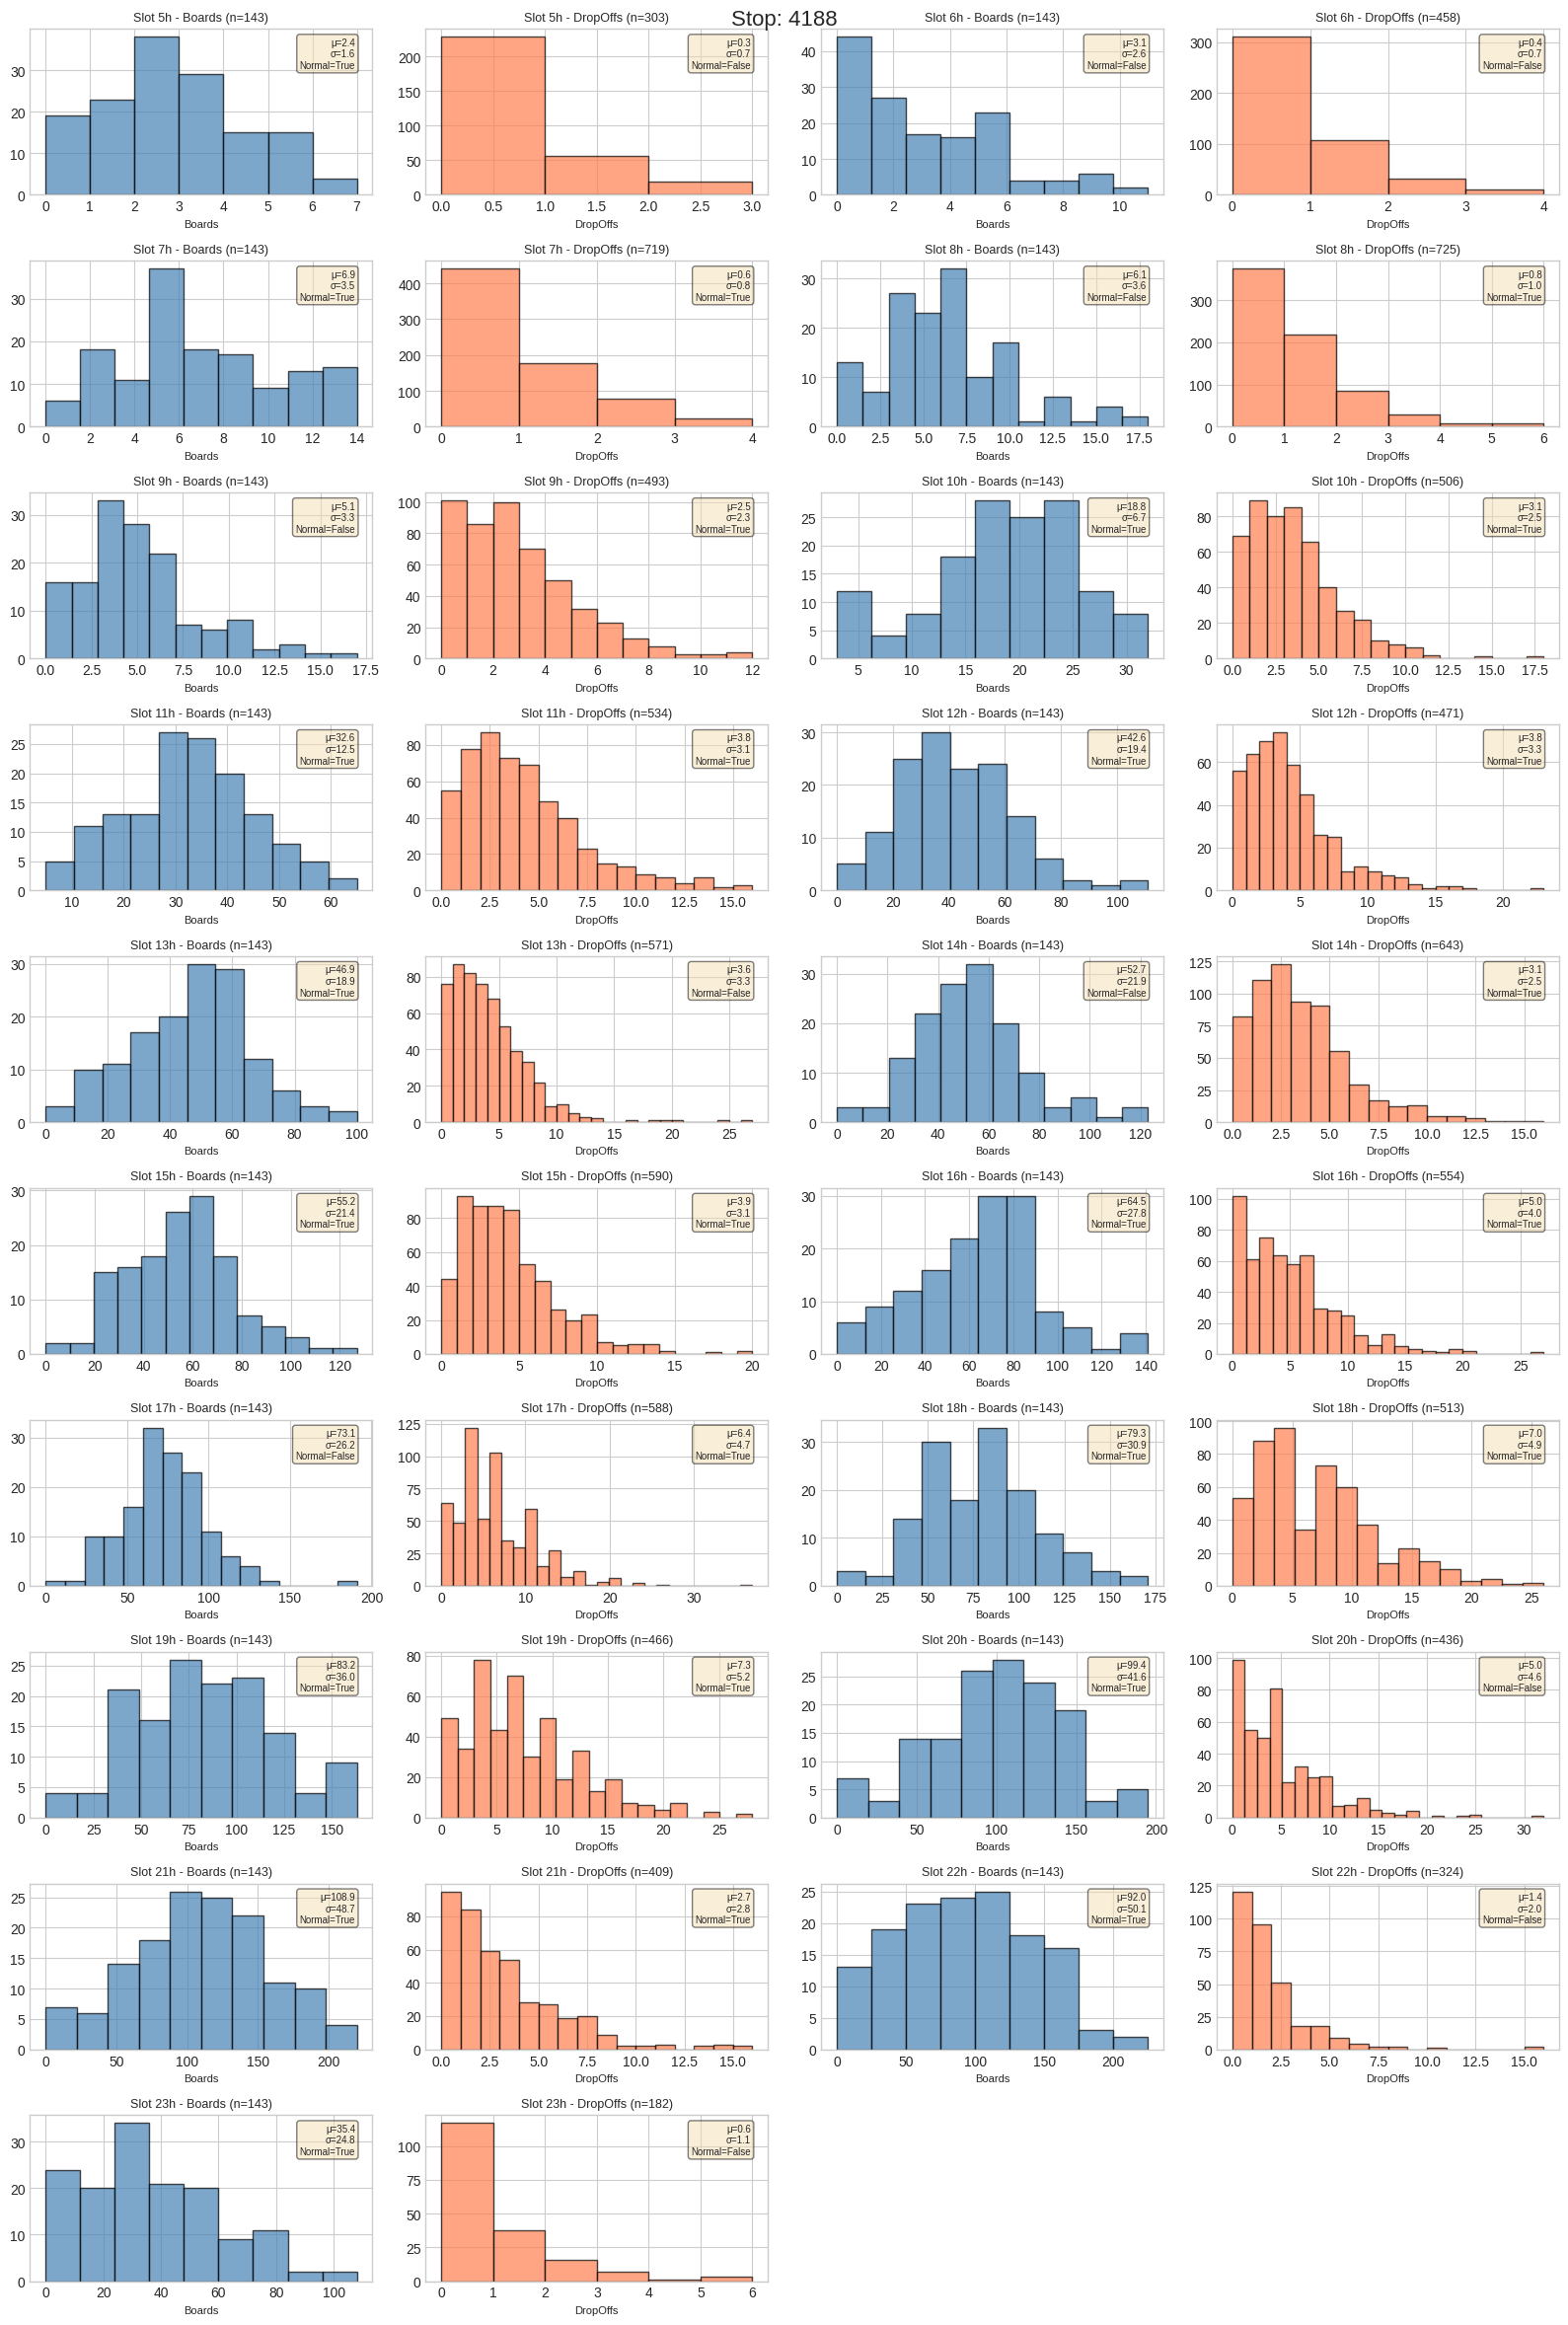





 Results obtained, for stop 2539:  
	Percentage of Normal Boards : 84.21%
	Percentage of Normal DropOffs : 84.21%


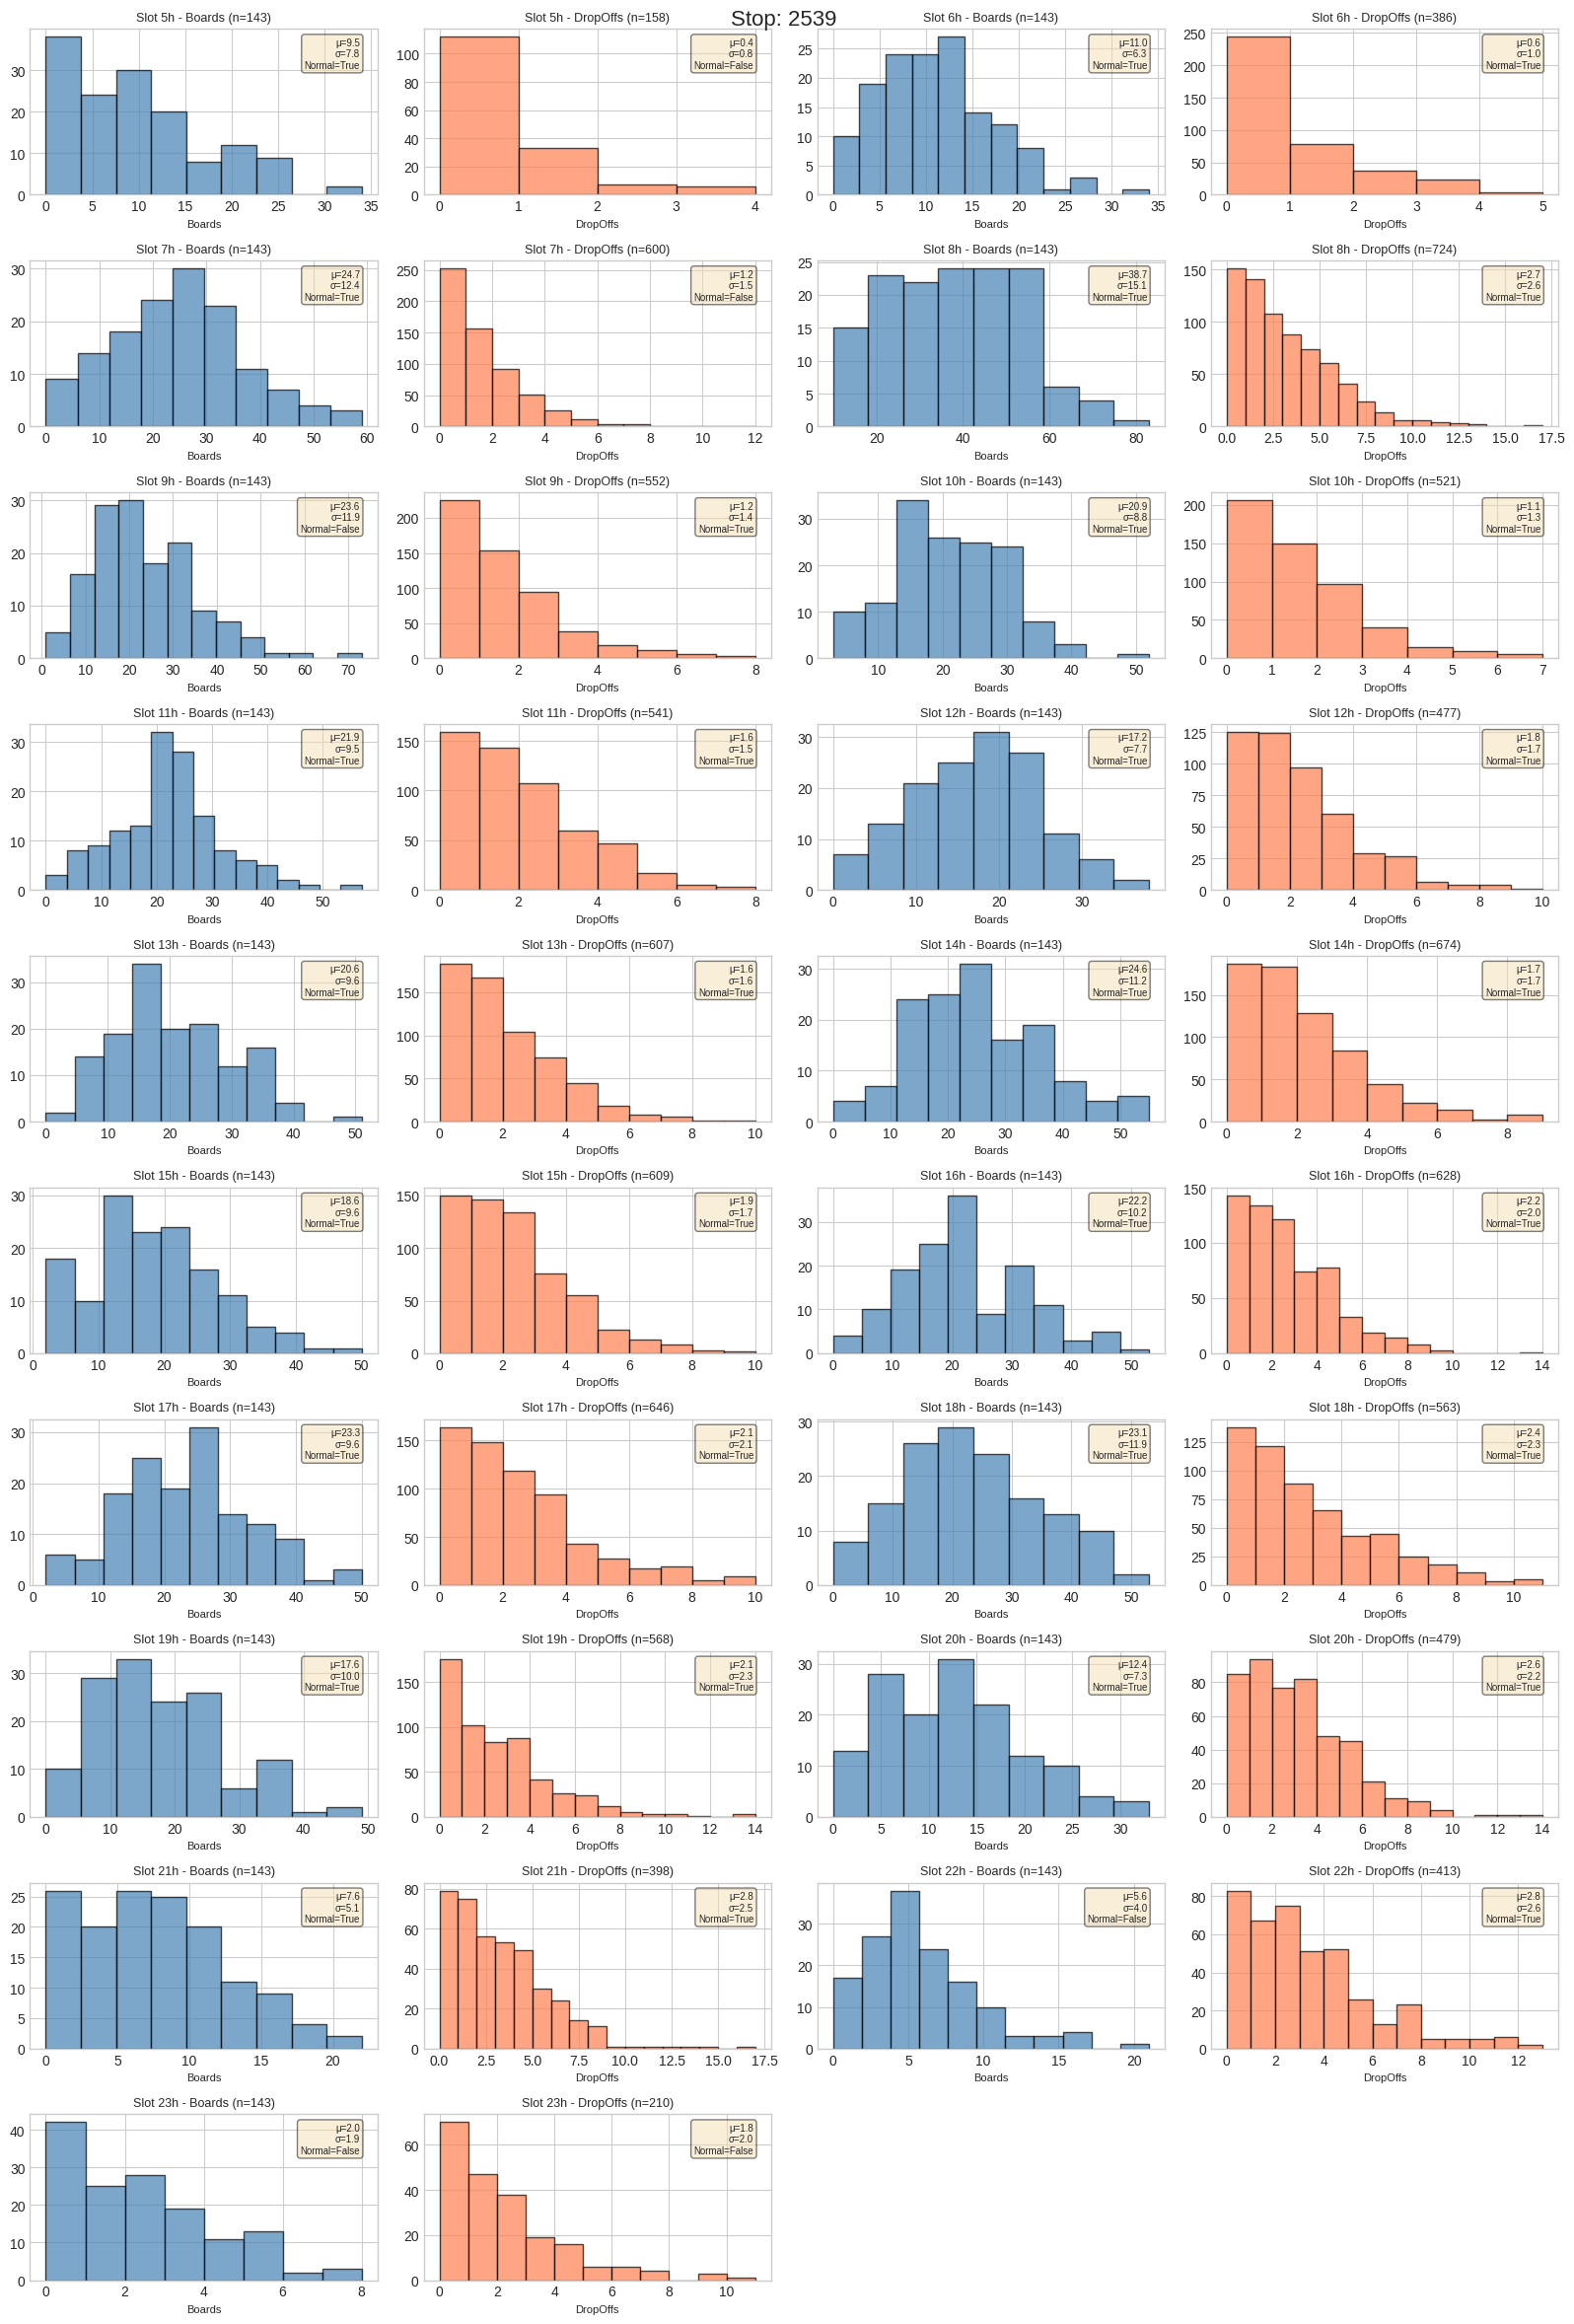

/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:41: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:38: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3






 Results obtained, for stop 2646:  
	Percentage of Normal Boards : 47.37%
	Percentage of Normal DropOffs : 0.00%


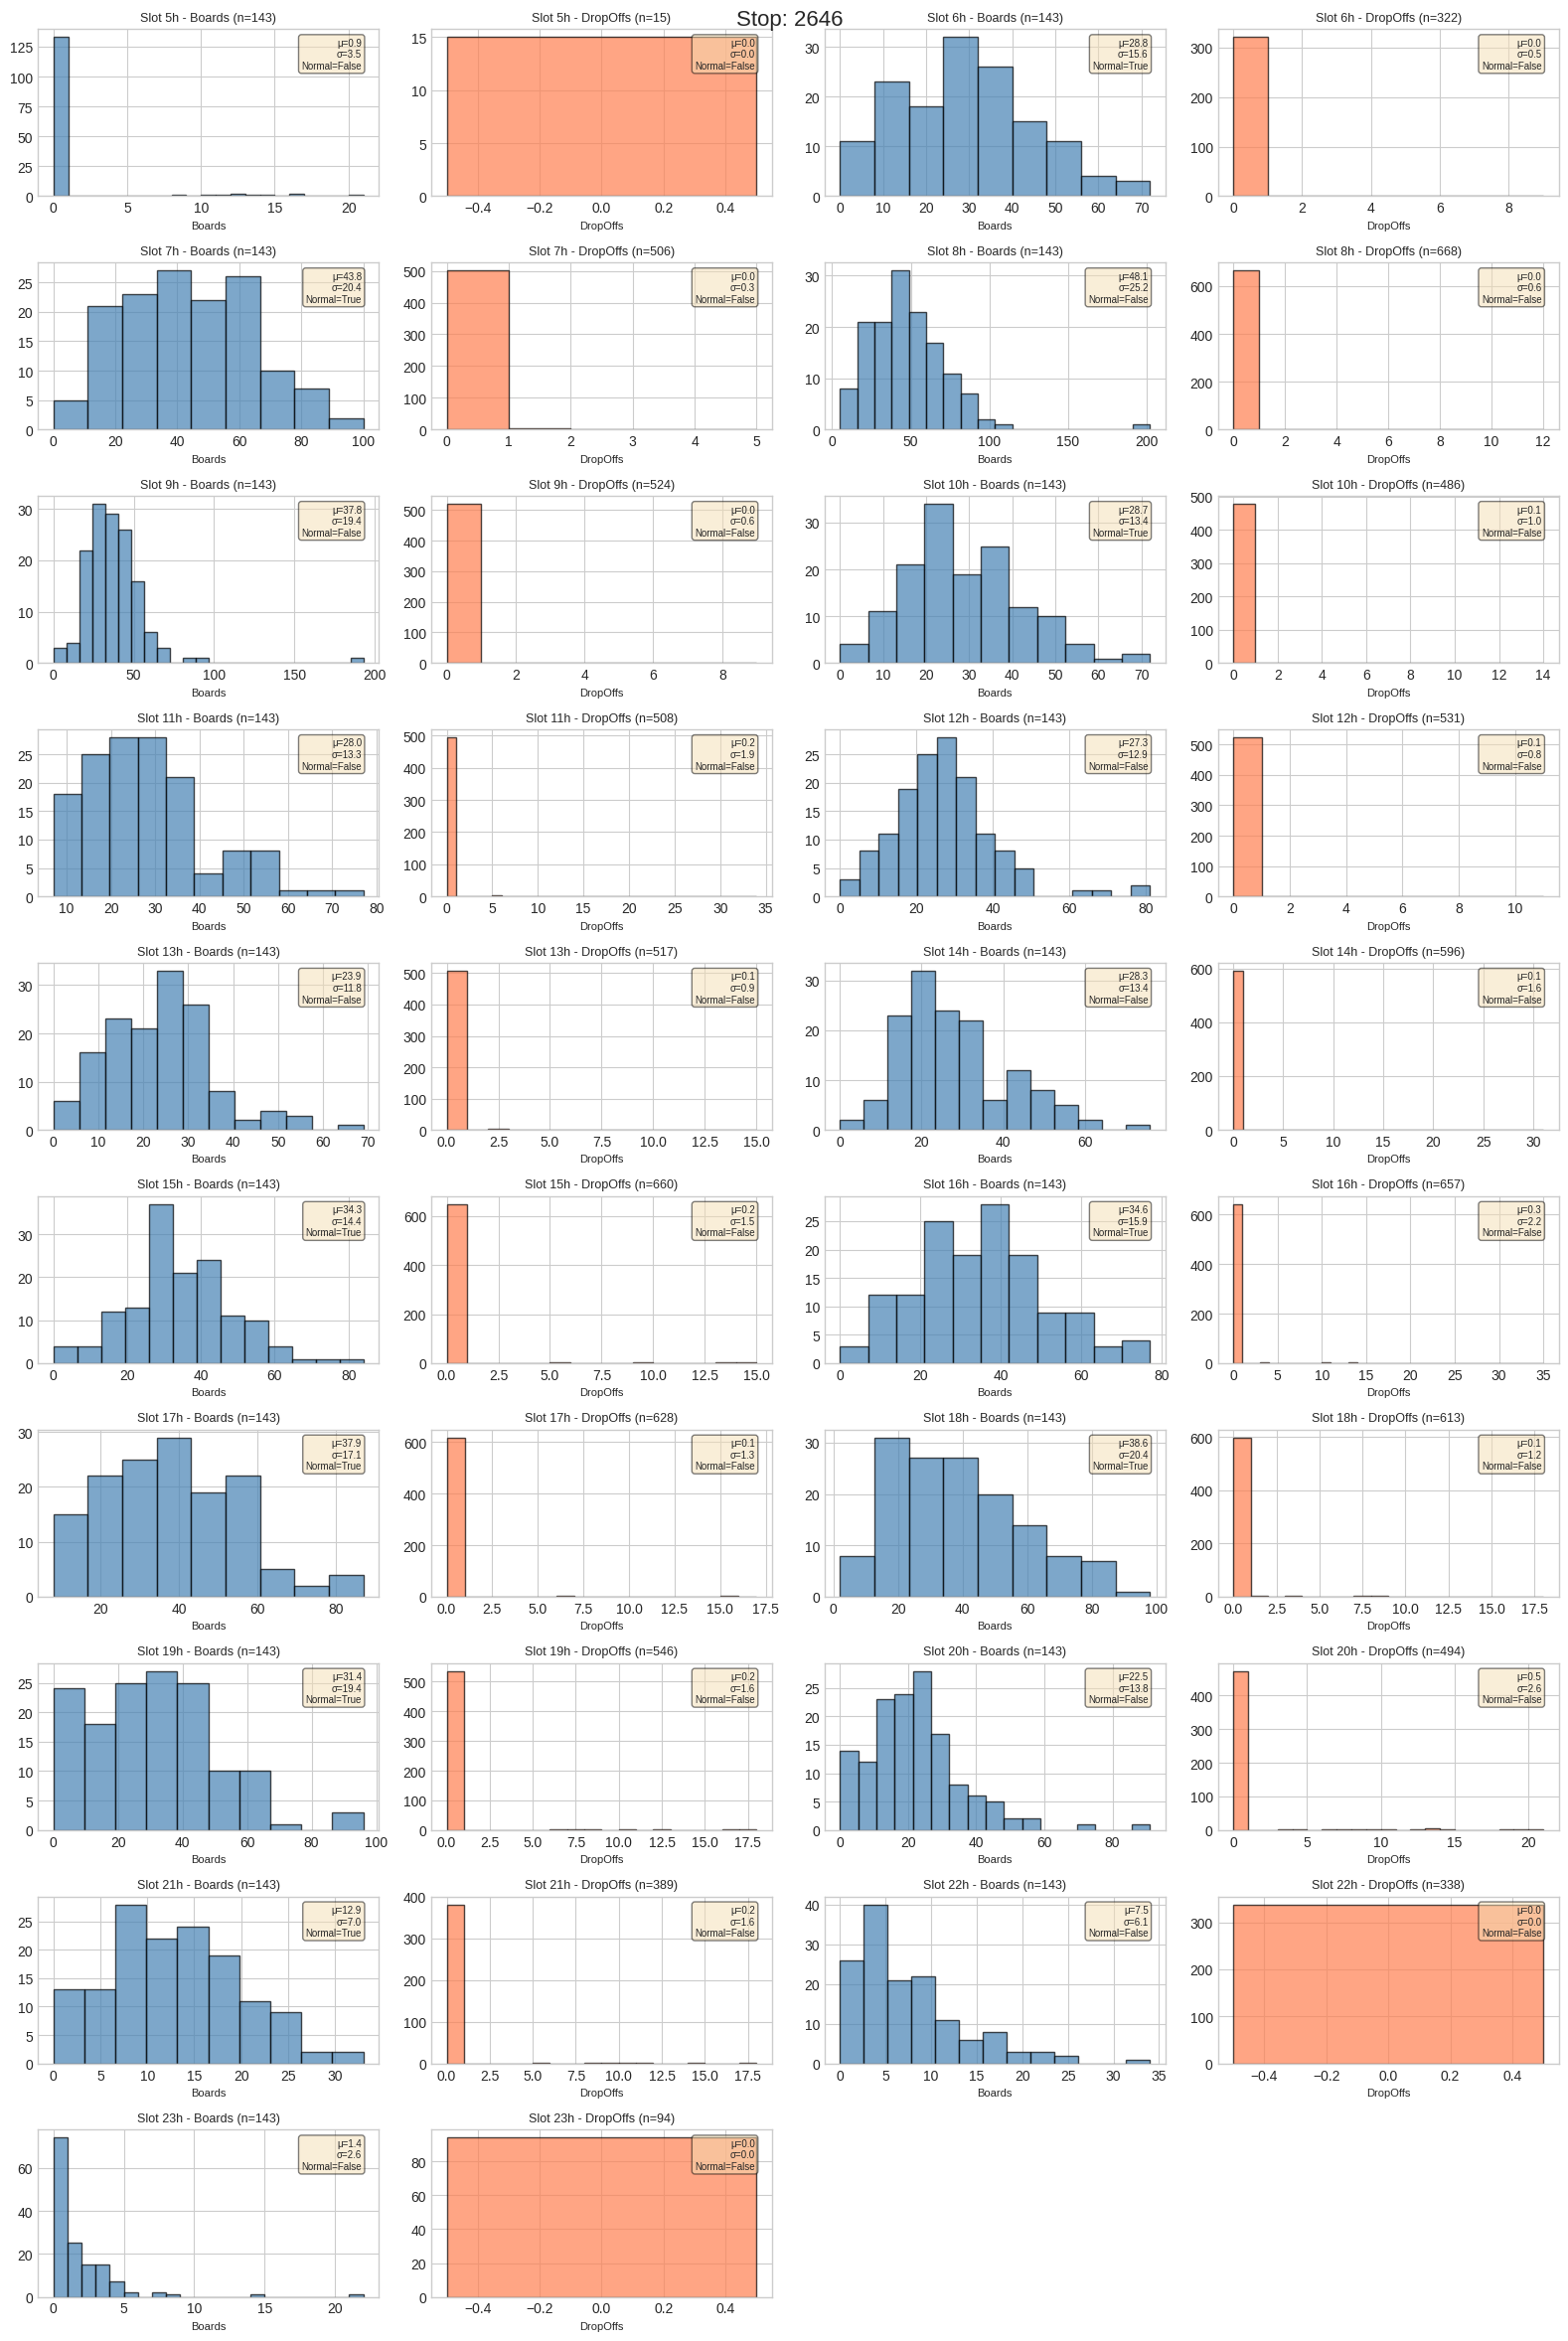





 Results obtained, for stop 5727:  
	Percentage of Normal Boards : 0.00%
	Percentage of Normal DropOffs : 89.47%


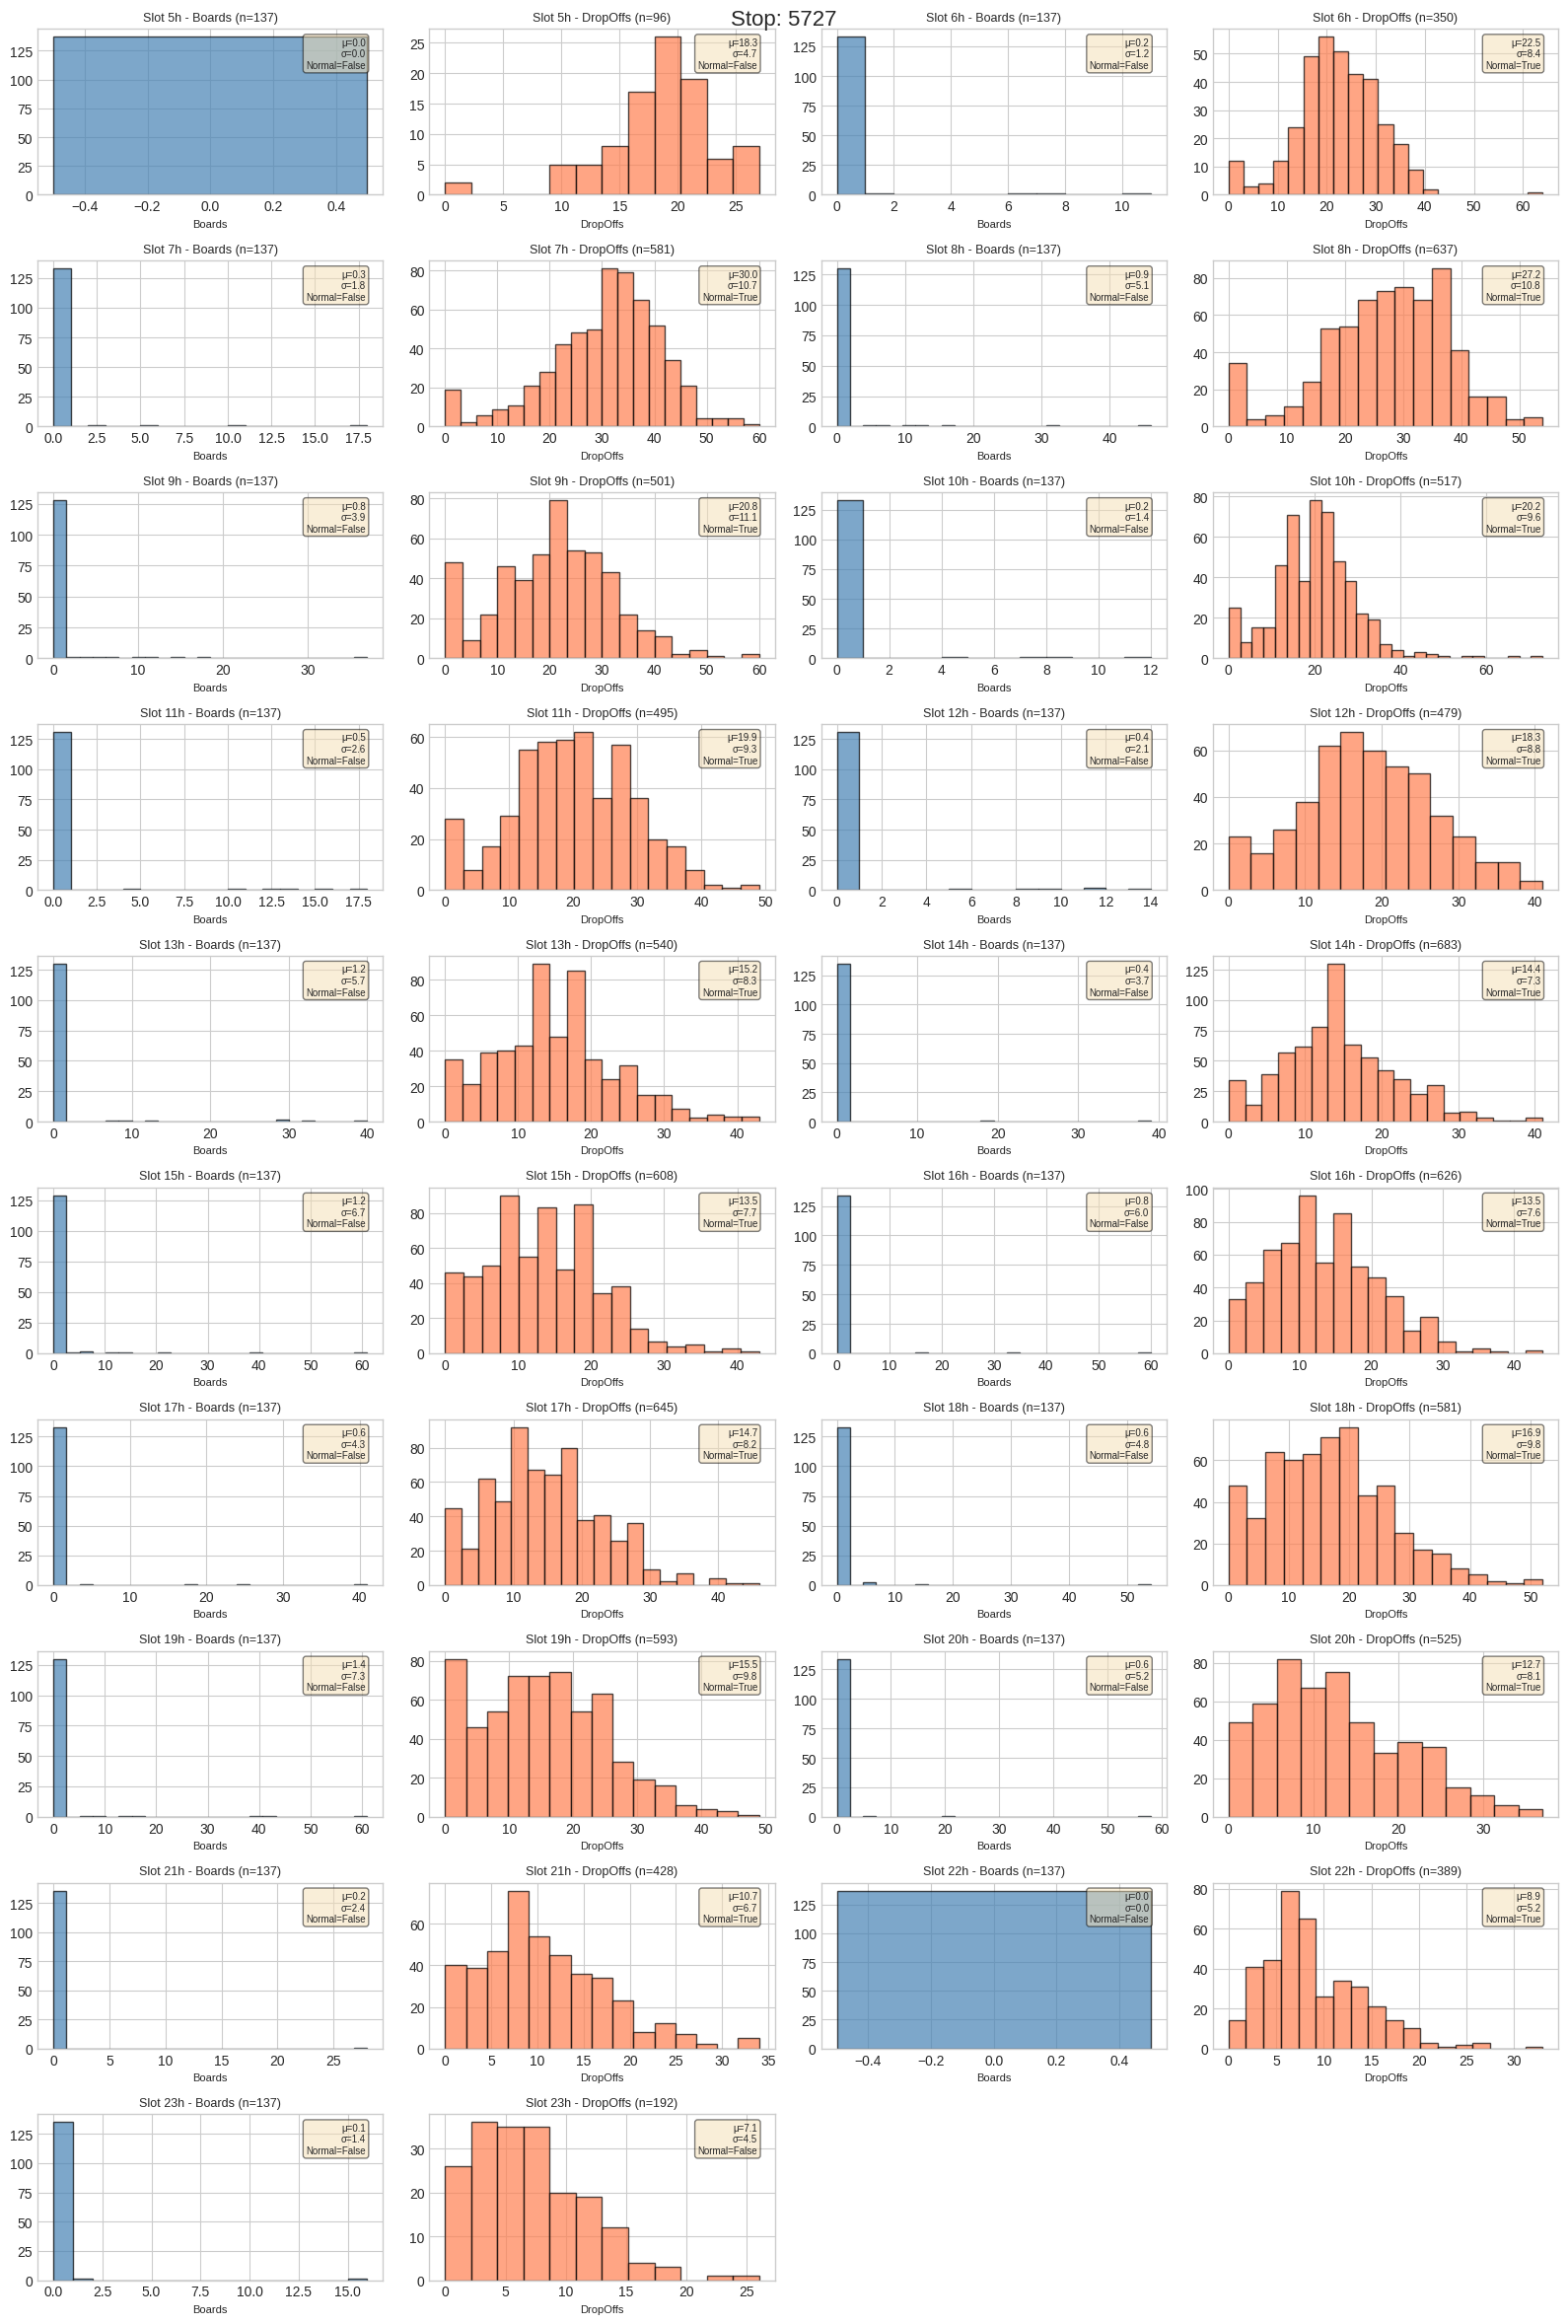





 Results obtained, for stop 3995:  
	Percentage of Normal Boards : 89.47%
	Percentage of Normal DropOffs : 57.89%


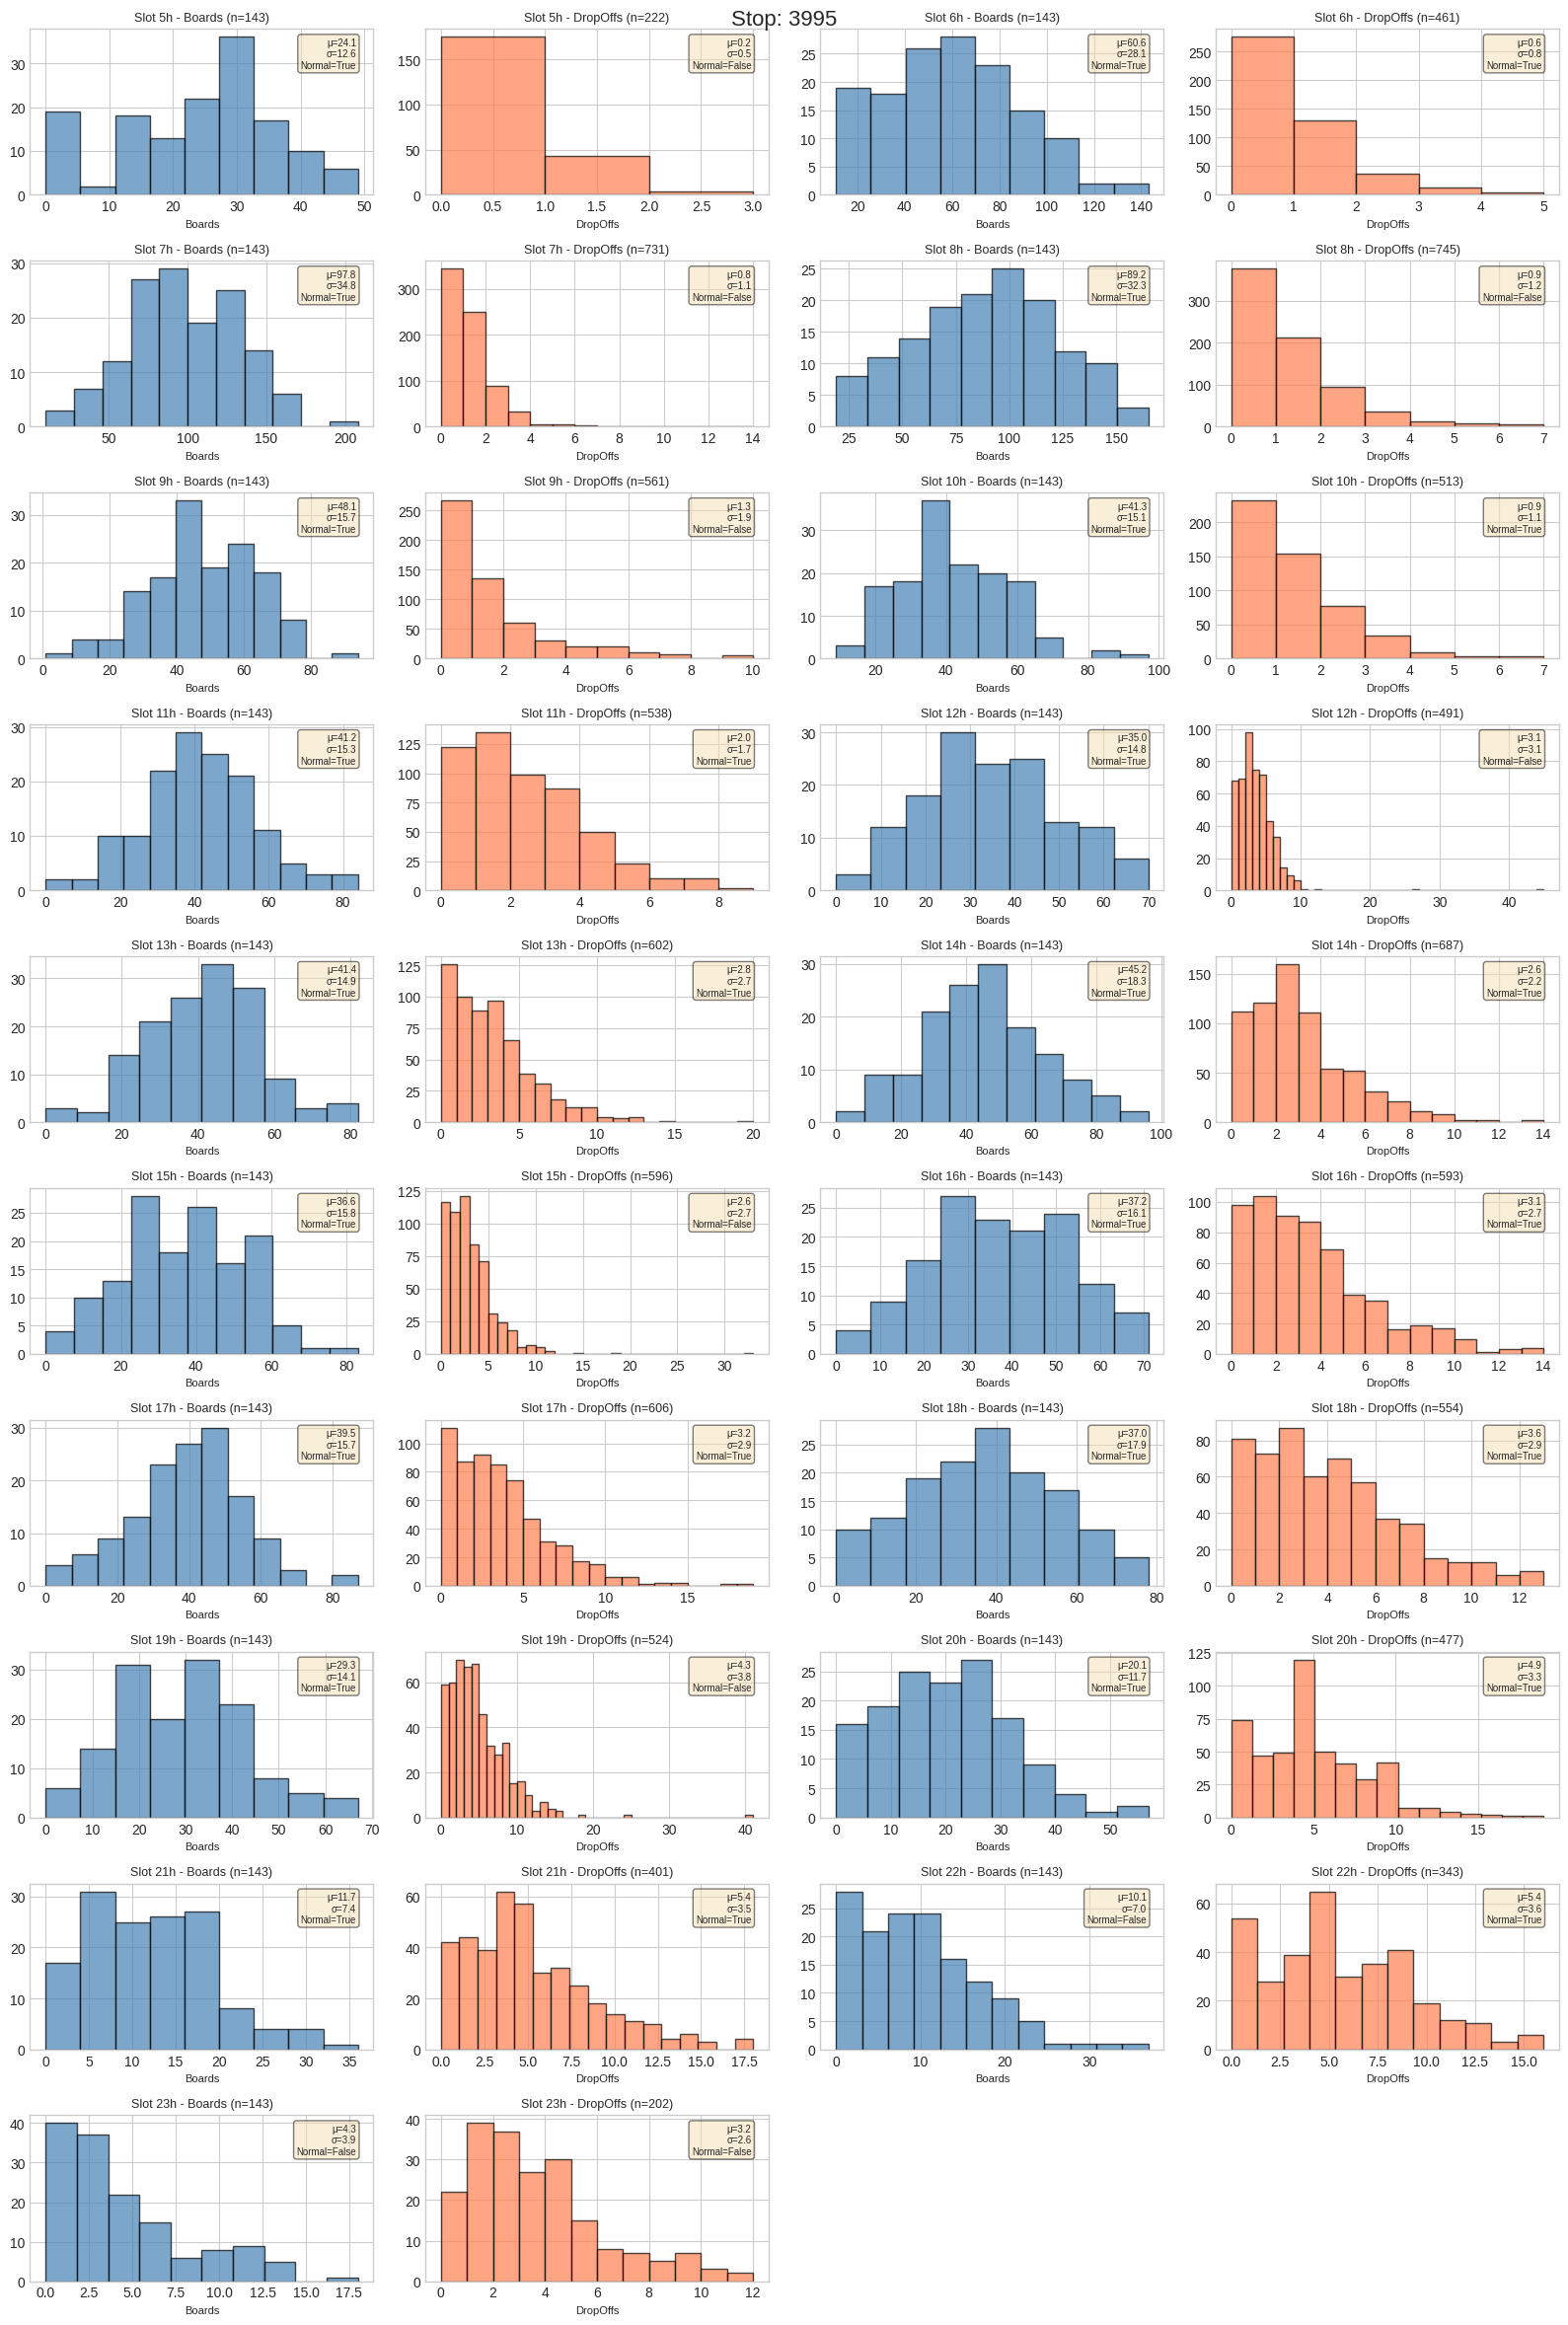





 Results obtained, for stop 2535:  
	Percentage of Normal Boards : 47.37%
	Percentage of Normal DropOffs : 73.68%


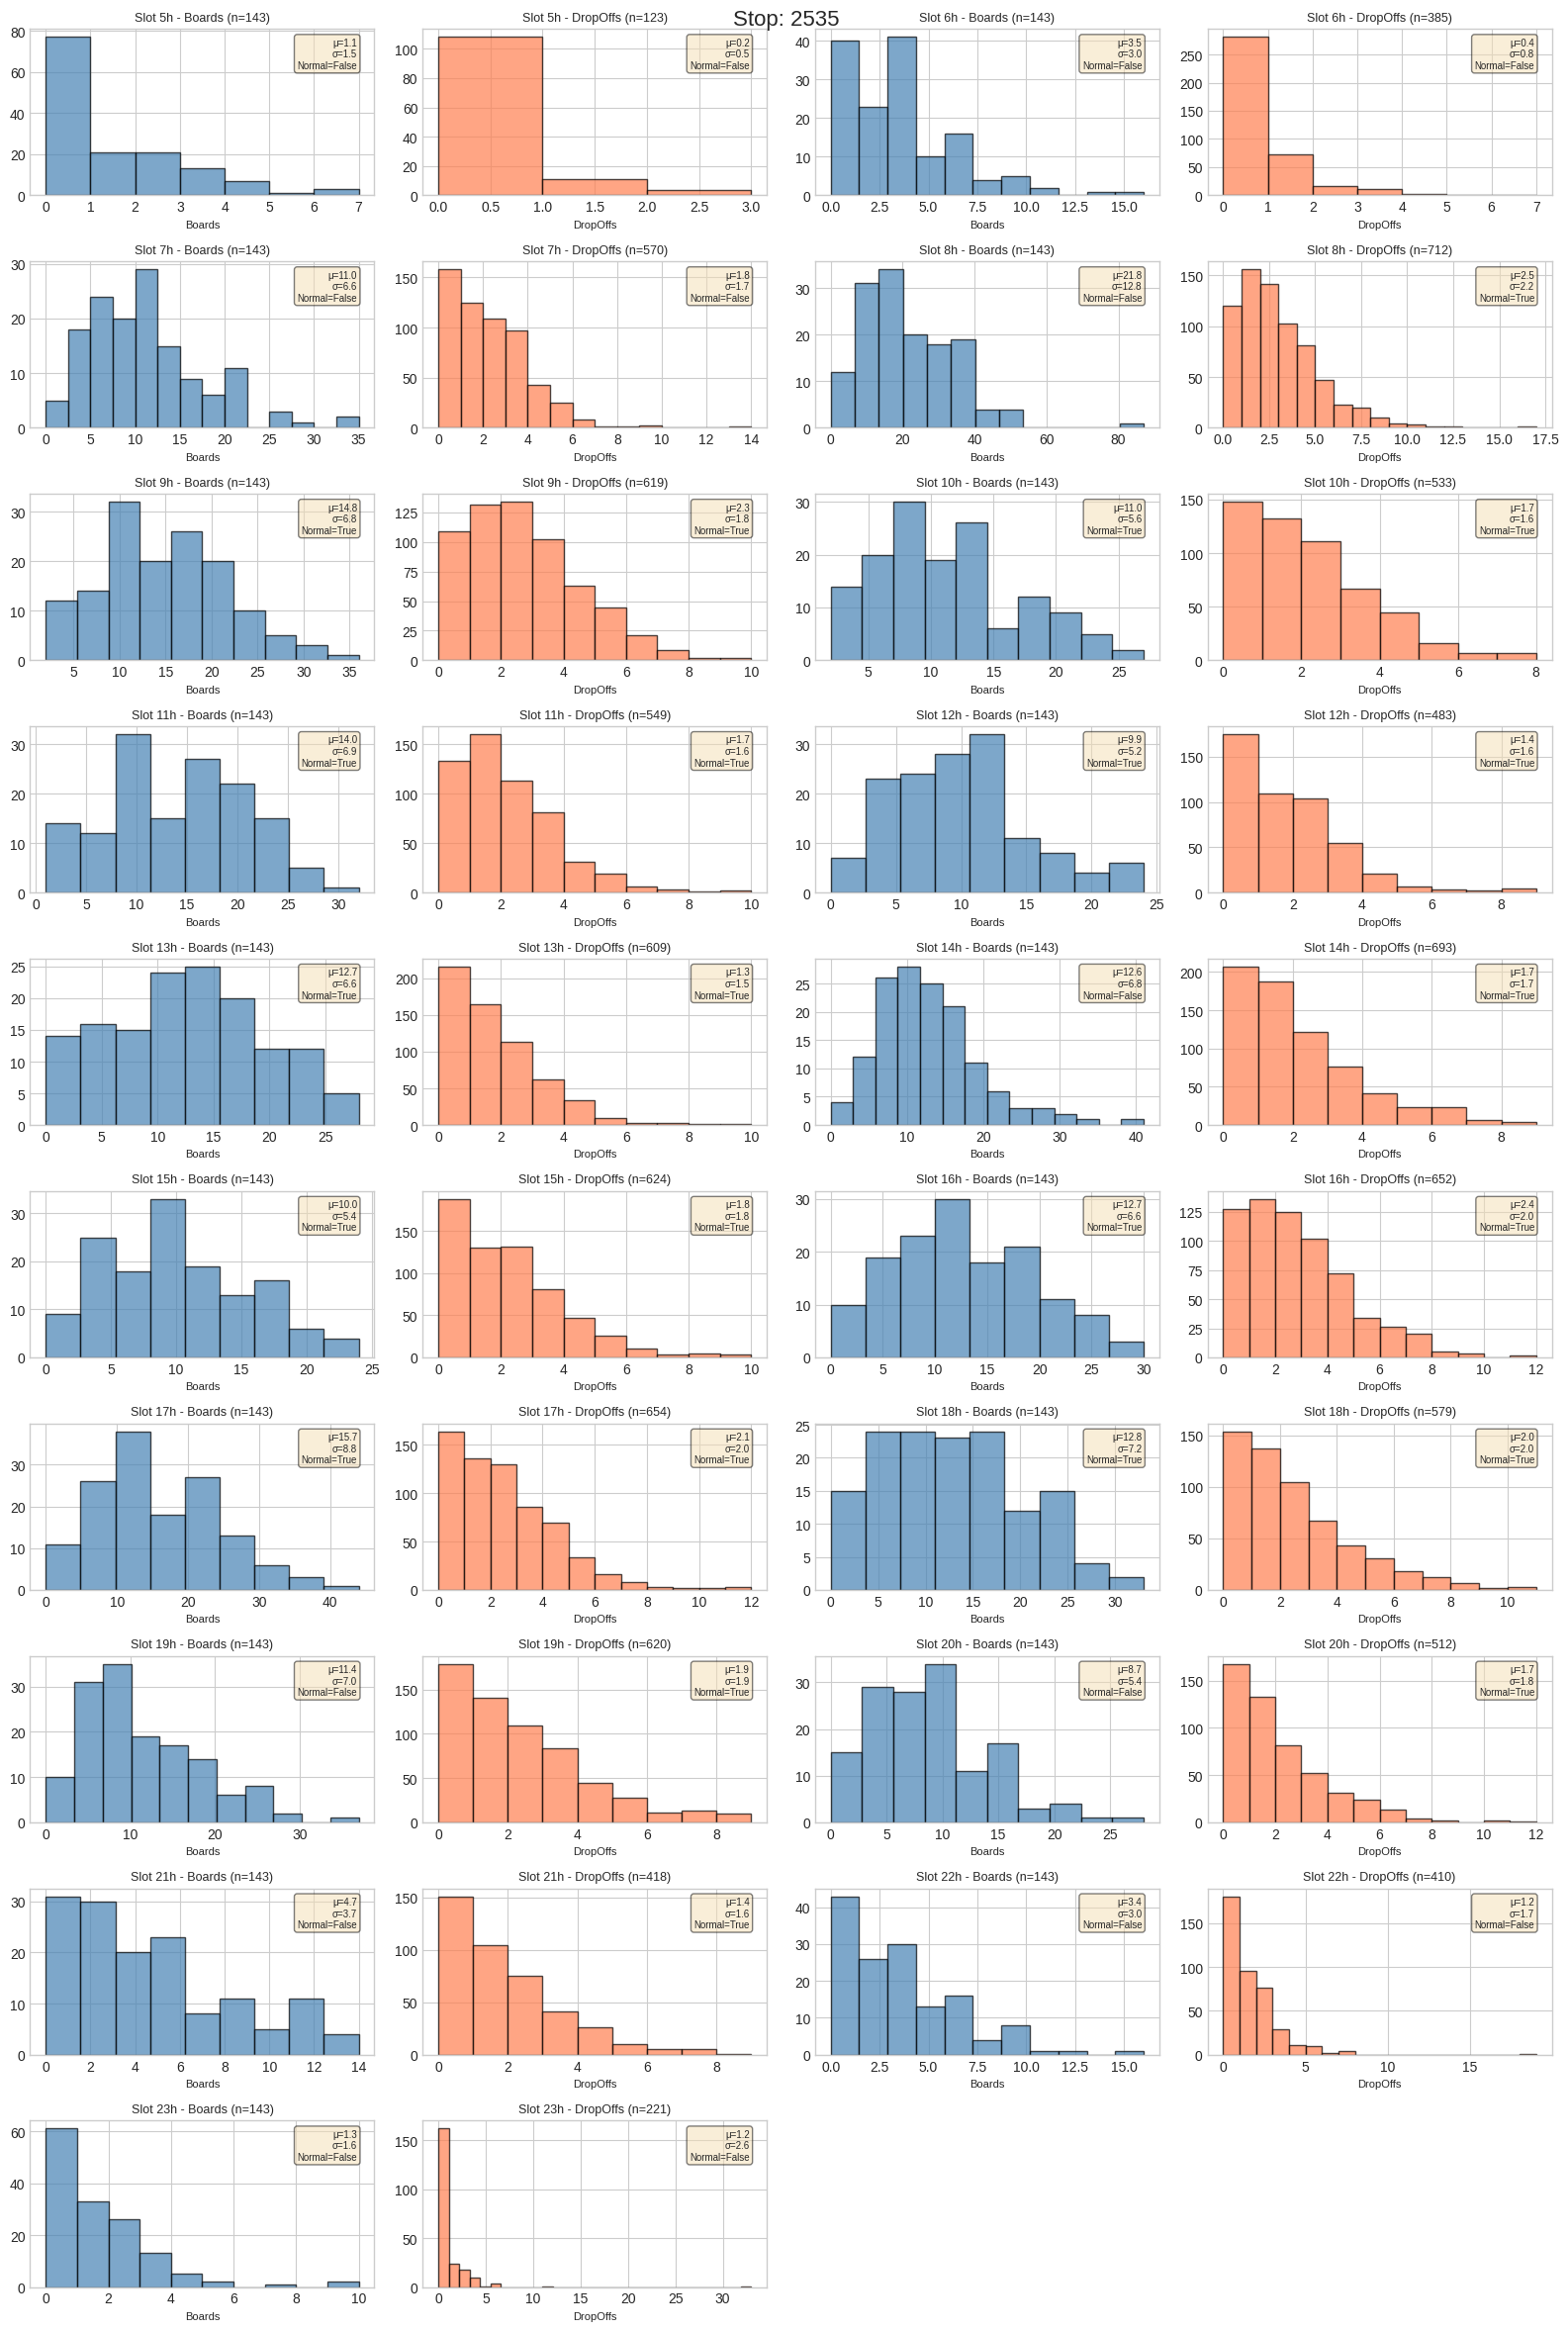





 GENERAL RESULTS:  
	Percentage of Normal Boards : 50.00%
	Percentage of Normal DropOffs : 50.38%


In [8]:
total_stops = final_dataframe["Stop"].unique()


timeslots = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]


counter_parameters = 0

global_normal_boards = 0
global_normal_dropoffs = 0


for stop in total_stops:


    data_per_stop = final_dataframe[final_dataframe["Stop"] == stop]


    fig, axes = plt.subplots(10, 4, figsize=(16, 24))
    fig.suptitle(f"Stop: {stop}", fontsize=16)

    plot_idx = 0

    counter_stop_parameters = 0
    stop_normal_boards = 0
    stop_normal_dropoffs = 0

    for timeslot in timeslots:
        data_boards = data_per_stop[f"instances_boards_{timeslot}"].iloc[0]
        data_dropoff = data_per_stop[f"instances_dropoffs_{timeslot}"].iloc[0]
        #data_dropoff = [np.log(val + 1) for val in data_dropoff]


        is_normal_b, instances_b, mean_val_b, std_val_b = is_normal_simplified(data_boards)


        row, col = plot_idx // 4, plot_idx % 4
        axes[row, col].hist(data_boards, bins='auto', edgecolor='black', alpha=0.7, color='steelblue')
        axes[row, col].set_title(f"Slot {timeslot}h - Boards (n={len(data_boards)})", fontsize=9)
        axes[row, col].set_xlabel("Boards", fontsize=8)
        axes[row, col].text(0.95, 0.95, f"μ={float(mean_val_b):.1f}\nσ={float(std_val_b):.1f}\nNormal={is_normal_b}",
            transform=axes[row, col].transAxes, fontsize=7, verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        plot_idx += 1


        is_normal_do, instances_do, mean_val_do, std_val_do = is_normal_simplified(data_dropoff)

        row, col = plot_idx // 4, plot_idx % 4
        axes[row, col].hist(data_dropoff, bins='auto', edgecolor='black', alpha=0.7, color='coral')
        axes[row, col].set_title(f"Slot {timeslot}h - DropOffs (n={len(data_dropoff)})", fontsize=9)
        axes[row, col].set_xlabel("DropOffs", fontsize=8)
        axes[row, col].text(0.95, 0.95, f"μ={float(mean_val_do):.1f}\nσ={float(std_val_do):.1f}\nNormal={is_normal_do}",
            transform=axes[row, col].transAxes, fontsize=7, verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        plot_idx += 1


        if is_normal_do:
            global_normal_dropoffs+= 1
            stop_normal_dropoffs += 1
        if is_normal_b:
            global_normal_boards += 1
            stop_normal_boards += 1

        counter_parameters += 1
        counter_stop_parameters += 1



    print(f"\n\n\n\n Results obtained, for stop {stop}:  \n\tPercentage of Normal Boards : {stop_normal_boards / counter_stop_parameters * 100:.2f}%"
          f"\n\tPercentage of Normal DropOffs : {stop_normal_dropoffs / counter_stop_parameters * 100:.2f}%")


    for i in range(plot_idx, 40):
        row, col = i // 4, i % 4
        axes[row, col].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"histograms_{stop}.png", dpi=150, bbox_inches='tight')
    plt.show()


print(f"\n\n\n\n GENERAL RESULTS:  \n\tPercentage of Normal Boards : {global_normal_boards / counter_parameters * 100:.2f}%"
          f"\n\tPercentage of Normal DropOffs : {global_normal_dropoffs / counter_parameters * 100:.2f}%")



# DESPUES DE MIS MARAVILLOSOS CAMBIOS(Soy basura)

In [12]:


# Definimos hardcoddeados 3 tipos de parada, De subida, de bajada y todoterreno.

# A las paradas de subida, hacemos que de 5 a 18 funcione de normal, y despues la lognormal del val + 1

# A las de descarga, lognormalizamos todas las de subida, dejamos como estan las de bajada


# A las todoterreno, lognormalizamos las de bajada, y lognormalizamos la franja de subida de las paradas de subida.


allroad = [3991, 3903, 1929, 4188, 2539, 3995, 2535]

dropoff_stop = [82, 4032, 5727]

board_stop = [2646, 562, 4090, 5939, 2646]

In [17]:
"""total_stops = final_dataframe["Stop"].unique()


timeslots = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]


counter_parameters = 0

global_normal_boards = 0
global_normal_dropoffs = 0


for stop in total_stops:


    data_per_stop = final_dataframe[final_dataframe["Stop"] == stop]


    fig, axes = plt.subplots(10, 4, figsize=(16, 24))
    fig.suptitle(f"Stop: {stop}", fontsize=16)

    plot_idx = 0

    counter_stop_parameters = 0
    stop_normal_boards = 0
    stop_normal_dropoffs = 0

    for timeslot in timeslots:
        data_boards = data_per_stop[f"instances_boards_{timeslot}"].iloc[0]
        data_dropoff = data_per_stop[f"instances_dropoffs_{timeslot}"].iloc[0]
        #data_dropoff = [np.log(val + 1) for val in data_dropoff]

        if (stop in allroad or stop in board_stop) and timeslot >=18:
            data_boards = [np.log(val +1) for val in data_boards]

        if stop in allroad:
            data_dropoff = [np.log(val + 1) for val in data_dropoff]


        if stop in dropoff_stop:
            data_boards = [np.log(val +1) for val in data_boards]
            #data_dropoff = [np.log(val + 1) for val in data_dropoff]




        is_normal_b, instances_b, mean_val_b, std_val_b = is_normal_simplified(data_boards)


        row, col = plot_idx // 4, plot_idx % 4
        axes[row, col].hist(data_boards, bins='auto', edgecolor='black', alpha=0.7, color='steelblue')
        axes[row, col].set_title(f"Slot {timeslot}h - Boards (n={len(data_boards)})", fontsize=9)
        axes[row, col].set_xlabel("Boards", fontsize=8)
        axes[row, col].text(0.95, 0.95, f"μ={float(mean_val_b):.1f}\nσ={float(std_val_b):.1f}\nNormal={is_normal_b}",
            transform=axes[row, col].transAxes, fontsize=7, verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        plot_idx += 1


        is_normal_do, instances_do, mean_val_do, std_val_do = is_normal_simplified(data_dropoff)

        row, col = plot_idx // 4, plot_idx % 4
        axes[row, col].hist(data_dropoff, bins='auto', edgecolor='black', alpha=0.7, color='coral')
        axes[row, col].set_title(f"Slot {timeslot}h - DropOffs (n={len(data_dropoff)})", fontsize=9)
        axes[row, col].set_xlabel("DropOffs", fontsize=8)
        axes[row, col].text(0.95, 0.95, f"μ={float(mean_val_do):.1f}\nσ={float(std_val_do):.1f}\nNormal={is_normal_do}",
            transform=axes[row, col].transAxes, fontsize=7, verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        plot_idx += 1


        if is_normal_do:
            global_normal_dropoffs+= 1
            stop_normal_dropoffs += 1
        if is_normal_b:
            global_normal_boards += 1
            stop_normal_boards += 1

        counter_parameters += 1
        counter_stop_parameters += 1



    print(f"\n\n\n\n Results obtained, for stop {stop}:  \n\tPercentage of Normal Boards : {stop_normal_boards / counter_stop_parameters * 100:.2f}%"
          f"\n\tPercentage of Normal DropOffs : {stop_normal_dropoffs / counter_stop_parameters * 100:.2f}%")


    for i in range(plot_idx, 40):
        row, col = i // 4, i % 4
        axes[row, col].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"histograms_{stop}.png", dpi=150, bbox_inches='tight')
    plt.show()


print(f"\n\n\n\n GENERAL RESULTS:  \n\tPercentage of Normal Boards : {global_normal_boards / counter_parameters * 100:.2f}%"
          f"\n\tPercentage of Normal DropOffs : {global_normal_dropoffs / counter_parameters * 100:.2f}%")

"""
;

''